In [ ]:
# ============================================================
# FiBL DOK PlanetScope Plot-Level Data Analysis
# For Google Colab
# analysis workflow
# ============================================================

# ------------------------------------------------------------
# 1. Install / import packages
# ------------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import kruskal

from sklearn.model_selection import GroupKFold, LeaveOneGroupOut, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    balanced_accuracy_score,
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings("ignore")

# Plot settings
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.grid"] = True

print("Packages loaded.")

Packages loaded.


In [ ]:
# ------------------------------------------------------------
# 2. Load CSV directly from Google Drive
# ------------------------------------------------------------

import pandas as pd

csv_file = "/content/FIBL_PlanetScope_2017_2019_WITH_CROPS.csv"

df = pd.read_csv(csv_file)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully.
Shape: (5403, 27)


,row_id,dok_plot_id,plot_id,BIO,GROUP,system_class,image_date,image_year,crop_type,2017,...,GNDVI_count,EVI_mean,EVI_stdDev,EVI_count,SAVI_mean,SAVI_stdDev,SAVI_count,MSAVI_mean,MSAVI_stdDev,MSAVI_count
0,0.0,2,2,M,c,CONTROL,2017-02-14,2017,winter wheat 1,winter wheat 1,...,20,0.046224,0.058804,20,0.013234,0.017232,20,0.011923,0.015579,20
1,1.0,1,1,N,c,CONTROL,2017-02-14,2017,winter wheat 1,winter wheat 1,...,18,0.096326,0.070133,18,0.025175,0.019086,18,0.022711,0.017268,18
2,2.0,30,30,O2,c,ORGANIC,2017-02-14,2017,winter wheat 1,winter wheat 1,...,18,0.047114,0.041874,18,0.012722,0.011862,18,0.011387,0.010696,18
3,3.0,29,29,O1,c,ORGANIC,2017-02-14,2017,winter wheat 1,winter wheat 1,...,16,0.033585,0.024600,16,0.008988,0.006803,16,0.008046,0.006110,16
4,4.0,7,7,D1,c,BIODYNAMIC,2017-02-14,2017,winter wheat 1,winter wheat 1,...,18,0.239080,0.081593,18,0.058001,0.020062,18,0.052670,0.018475,18


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# ============================================================
# FiBL DOK PlanetScope Plot-Level Data Analysis
# For Google Colab
# Author: Petros Stratis - draft analysis workflow
# ============================================================

# ------------------------------------------------------------
# 1. Install / import packages
# ------------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import kruskal

from sklearn.model_selection import GroupKFold, LeaveOneGroupOut, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    balanced_accuracy_score,
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings("ignore")

# Plot settings
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.grid"] = True

print("Packages loaded.")

Packages loaded.


In [ ]:
# ------------------------------------------------------------
# 3. Standardise column names for the analysis
# ------------------------------------------------------------

df = df.rename(columns={
    "image_date": "date",
    "image_year": "year",
    "crop_type": "crop",
    "system_class": "treatment_class",
    "NDVI_stdDev": "NDVI_std",
    "GNDVI_stdDev": "GNDVI_std",
    "EVI_stdDev": "EVI_std",
    "SAVI_stdDev": "SAVI_std",
    "MSAVI_stdDev": "MSAVI_std",
    "NDVI_count": "valid_pixels"
})

df["date"] = pd.to_datetime(df["date"])
df["month"] = df["date"].dt.month

print(df.columns.tolist())
df.head()

['row_id', 'dok_plot_id', 'plot_id', 'BIO', 'GROUP', 'treatment_class', 'date', 'year', 'crop', '2017', '2018', '2019', 'NDVI_mean', 'NDVI_std', 'valid_pixels', 'GNDVI_mean', 'GNDVI_std', 'GNDVI_count', 'EVI_mean', 'EVI_std', 'EVI_count', 'SAVI_mean', 'SAVI_std', 'SAVI_count', 'MSAVI_mean', 'MSAVI_std', 'MSAVI_count', 'month']


,row_id,dok_plot_id,plot_id,BIO,GROUP,treatment_class,date,year,crop,2017,...,EVI_mean,EVI_std,EVI_count,SAVI_mean,SAVI_std,SAVI_count,MSAVI_mean,MSAVI_std,MSAVI_count,month
0,0.0,2,2,M,c,CONTROL,2017-02-14,2017,winter wheat 1,winter wheat 1,...,0.046224,0.058804,20,0.013234,0.017232,20,0.011923,0.015579,20,2
1,1.0,1,1,N,c,CONTROL,2017-02-14,2017,winter wheat 1,winter wheat 1,...,0.096326,0.070133,18,0.025175,0.019086,18,0.022711,0.017268,18,2
2,2.0,30,30,O2,c,ORGANIC,2017-02-14,2017,winter wheat 1,winter wheat 1,...,0.047114,0.041874,18,0.012722,0.011862,18,0.011387,0.010696,18,2
3,3.0,29,29,O1,c,ORGANIC,2017-02-14,2017,winter wheat 1,winter wheat 1,...,0.033585,0.024600,16,0.008988,0.006803,16,0.008046,0.006110,16,2
4,4.0,7,7,D1,c,BIODYNAMIC,2017-02-14,2017,winter wheat 1,winter wheat 1,...,0.239080,0.081593,18,0.058001,0.020062,18,0.052670,0.018475,18,2


In [ ]:
# ------------------------------------------------------------
# 4. Define vegetation-index columns
# ------------------------------------------------------------

vi_mean_cols = []

for col in ["NDVI_mean", "GNDVI_mean", "SAVI_mean", "MSAVI_mean", "EVI_mean"]:
    if col in df.columns:
        vi_mean_cols.append(col)

vi_std_cols = []

for col in ["NDVI_std", "GNDVI_std", "SAVI_std", "MSAVI_std", "EVI_std"]:
    if col in df.columns:
        vi_std_cols.append(col)

print("VI mean columns:", vi_mean_cols)
print("VI std columns:", vi_std_cols)

VI mean columns: ['NDVI_mean', 'GNDVI_mean', 'SAVI_mean', 'MSAVI_mean', 'EVI_mean']
VI std columns: ['NDVI_std', 'GNDVI_std', 'SAVI_std', 'MSAVI_std', 'EVI_std']


In [ ]:
# ------------------------------------------------------------
# 5. Define detailed and broad treatment groups
# ------------------------------------------------------------

def assign_detailed_class(bio):
    if bio in ["D1", "D2"]:
        return "biodynamic"
    elif bio in ["O1", "O2"]:
        return "organic"
    elif bio in ["K1", "K2"]:
        return "conventional_fym"
    elif bio == "M":
        return "mineral_conventional"
    elif bio == "N":
        return "nofert_control"
    else:
        return np.nan

df["detailed_class"] = df["BIO"].apply(assign_detailed_class)

# Main broad scenario: M included as input-based
def assign_broad_class_with_M(bio):
    if bio in ["D1", "D2", "O1", "O2"]:
        return "organic_based"
    elif bio in ["K1", "K2", "M"]:
        return "input_based"
    elif bio == "N":
        return "nofert_control"
    else:
        return np.nan

df["broad_class_with_M"] = df["BIO"].apply(assign_broad_class_with_M)

# Sensitivity scenario: M excluded from two-class model
def assign_broad_class_without_M(bio):
    if bio in ["D1", "D2", "O1", "O2"]:
        return "organic_based"
    elif bio in ["K1", "K2"]:
        return "input_based"
    elif bio == "M":
        return "mineral_conventional_excluded"
    elif bio == "N":
        return "nofert_control"
    else:
        return np.nan

df["broad_class_without_M"] = df["BIO"].apply(assign_broad_class_without_M)

print("Detailed class counts:")
print(df["detailed_class"].value_counts(dropna=False))

print("\nBroad class with M included:")
print(df["broad_class_with_M"].value_counts(dropna=False))

print("\nBroad class with M excluded:")
print(df["broad_class_without_M"].value_counts(dropna=False))

Detailed class counts:
detailed_class
biodynamic              1353
conventional_fym        1350
organic                 1350
mineral_conventional     675
nofert_control           675
Name: count, dtype: int64

Broad class with M included:
broad_class_with_M
organic_based     2703
input_based       2025
nofert_control     675
Name: count, dtype: int64

Broad class with M excluded:
broad_class_without_M
organic_based                    2703
input_based                      1350
nofert_control                    675
mineral_conventional_excluded     675
Name: count, dtype: int64


In [ ]:
# ------------------------------------------------------------
# 6. Check crops, treatments and analysis groups
# ------------------------------------------------------------

print("Original treatment classes:")
print(df["treatment_class"].value_counts(dropna=False))

print("\nBIO codes:")
print(df["BIO"].value_counts(dropna=False))

print("\nDetailed classes:")
print(df["detailed_class"].value_counts(dropna=False))

print("\nBroad classes with M included:")
print(df["broad_class_with_M"].value_counts(dropna=False))

print("\nBroad classes with M excluded:")
print(df["broad_class_without_M"].value_counts(dropna=False))

print("\nCrops:")
print(df["crop"].value_counts(dropna=False))

print("\nYears:")
print(df["year"].value_counts(dropna=False).sort_index())

print("\nCrop x Year counts:")
print(pd.crosstab(df["crop"], df["year"]))

Original treatment classes:
treatment_class
BIODYNAMIC      1353
CONTROL         1350
ORGANIC         1350
CONVENTIONAL    1350
Name: count, dtype: int64

BIO codes:
BIO
D2    677
D1    676
M     675
N     675
O1    675
O2    675
K2    675
K1    675
Name: count, dtype: int64

Detailed classes:
detailed_class
biodynamic              1353
conventional_fym        1350
organic                 1350
mineral_conventional     675
nofert_control           675
Name: count, dtype: int64

Broad classes with M included:
broad_class_with_M
organic_based     2703
input_based       2025
nofert_control     675
Name: count, dtype: int64

Broad classes with M excluded:
broad_class_without_M
organic_based                    2703
input_based                      1350
nofert_control                    675
mineral_conventional_excluded     675
Name: count, dtype: int64

Crops:
crop
winter wheat 1    1386
potatoes          1184
winter wheat 2    1032
grass-clover 1     768
soybeans           617
grass-clover 

In [ ]:
# ------------------------------------------------------------
# 7. Check vegetation index correctness and suspicious values
# ------------------------------------------------------------

vi_cols_to_check = [
    "NDVI_mean", "GNDVI_mean", "EVI_mean", "SAVI_mean", "MSAVI_mean",
    "NDVI_std", "GNDVI_std", "EVI_std", "SAVI_std", "MSAVI_std"
]

existing_vi_cols = [c for c in vi_cols_to_check if c in df.columns]

print("Existing VI columns:")
print(existing_vi_cols)

print("\nBasic descriptive statistics:")
display(df[existing_vi_cols].describe().T)

# Count values outside expected broad ranges
# NDVI, GNDVI, SAVI, MSAVI should normally be roughly between -1 and 1
# EVI can occasionally exceed this slightly, but very large values are suspicious

range_checks = []

for col in existing_vi_cols:
    values = df[col].dropna()

    if "EVI" in col:
        normal_min, normal_max = -1, 1
        broad_min, broad_max = -2, 2
    else:
        normal_min, normal_max = -1, 1
        broad_min, broad_max = -1, 1

    n_total = len(values)
    n_out_normal = ((values < normal_min) | (values > normal_max)).sum()
    n_out_broad = ((values < broad_min) | (values > broad_max)).sum()

    range_checks.append({
        "column": col,
        "n_total": n_total,
        "min": values.min(),
        "max": values.max(),
        "mean": values.mean(),
        "std": values.std(),
        "outside_-1_1": n_out_normal,
        "outside_broad_range": n_out_broad
    })

range_check_df = pd.DataFrame(range_checks)

print("\nRange check summary:")
display(range_check_df)

# Show suspicious EVI values
if "EVI_mean" in df.columns:
    print("\nMost extreme EVI_mean values:")
    display(
        df.loc[
            df["EVI_mean"].abs().sort_values(ascending=False).head(20).index,
            ["plot_id", "BIO", "detailed_class", "date", "year", "month", "crop", "EVI_mean", "EVI_std", "valid_pixels"]
        ]
    )

Existing VI columns:
['NDVI_mean', 'GNDVI_mean', 'EVI_mean', 'SAVI_mean', 'MSAVI_mean', 'NDVI_std', 'GNDVI_std', 'EVI_std', 'SAVI_std', 'MSAVI_std']

Basic descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
NDVI_mean,5403.0,0.312636,0.124386,0.006106,0.213955,0.316674,0.413271,0.622358
GNDVI_mean,5403.0,0.228198,0.105357,-0.062418,0.148356,0.233874,0.311827,0.516873
EVI_mean,5403.0,1.481976,27.857764,-796.726705,0.797390,1.237281,1.747053,1699.332724
SAVI_mean,5403.0,0.314831,0.136594,0.004745,0.200733,0.320596,0.420290,0.729434
MSAVI_mean,5403.0,0.313532,0.137182,0.004276,0.198654,0.321027,0.421412,0.693332
NDVI_std,5403.0,0.033115,0.019177,0.000000,0.018507,0.028116,0.044297,0.140068
GNDVI_std,5403.0,0.026059,0.014629,0.000000,0.014981,0.022287,0.034120,0.099861
EVI_std,5403.0,5.590939,75.850519,0.000000,0.095416,0.150763,0.251485,2934.538368
SAVI_std,5403.0,0.033825,0.019517,0.000000,0.018659,0.029179,0.045386,0.132348
MSAVI_std,5403.0,0.033443,0.019420,0.000000,0.018277,0.028816,0.045173,0.133198



Range check summary:


,column,n_total,min,max,mean,std,outside_-1_1,outside_broad_range
0,NDVI_mean,5403,0.006106,0.622358,0.312636,0.124386,0,0
1,GNDVI_mean,5403,-0.062418,0.516873,0.228198,0.105357,0,0
2,EVI_mean,5403,-796.726705,1699.332724,1.481976,27.857764,3582,1076
3,SAVI_mean,5403,0.004745,0.729434,0.314831,0.136594,0,0
4,MSAVI_mean,5403,0.004276,0.693332,0.313532,0.137182,0,0
5,NDVI_std,5403,0.000000,0.140068,0.033115,0.019177,0,0
6,GNDVI_std,5403,0.000000,0.099861,0.026059,0.014629,0,0
7,EVI_std,5403,0.000000,2934.538368,5.590939,75.850519,300,197
8,SAVI_std,5403,0.000000,0.132348,0.033825,0.019517,0,0
9,MSAVI_std,5403,0.000000,0.133198,0.033443,0.019420,0,0



Most extreme EVI_mean values:


,plot_id,BIO,detailed_class,date,year,month,crop,EVI_mean,EVI_std,valid_pixels
4396,12,D2,biodynamic,2019-03-23,2019,3,grass-clover 2,1699.332724,2934.538368,21
4435,37,N,nofert_control,2019-03-23,2019,3,potatoes,-796.726705,2169.880862,19
4382,27,O1,organic,2019-03-23,2019,3,grass-clover 2,408.042170,2140.519401,17
4395,33,K1,conventional_fym,2019-03-23,2019,3,grass-clover 2,-248.610834,377.734383,18
4392,56,M,mineral_conventional,2019-03-23,2019,3,grass-clover 2,221.808026,1296.937218,18
4427,32,K2,conventional_fym,2019-03-23,2019,3,potatoes,201.657291,860.426515,17
4376,64,K2,conventional_fym,2019-03-23,2019,3,winter wheat 2,-176.887329,726.418160,18
4406,61,K1,conventional_fym,2019-03-23,2019,3,grass-clover 2,-174.712142,235.771464,18
4393,55,N,nofert_control,2019-03-23,2019,3,grass-clover 2,165.341510,1307.609380,18
4400,18,O2,organic,2019-03-23,2019,3,grass-clover 2,-145.438191,402.804404,18


In [ ]:
# ------------------------------------------------------------
# 7. Broad grouping: organic-based vs input-based
# ------------------------------------------------------------

def broad_group(x):
    x = str(x).upper().strip()

    if x in ["BIODYNAMIC", "ORGANIC"]:
        return "Organic-based"
    elif x in ["CONVENTIONAL", "MINERAL", "CONFYM", "CONMIN"]:
        return "Input-based"
    elif x in ["CONTROL", "NOFERT", "UNFERTILISED CONTROL", "UNFERTILIZED CONTROL"]:
        return np.nan
    else:
        return np.nan

df["broad_class"] = df["treatment_class"].apply(broad_group)

print(df[["BIO", "GROUP", "treatment_class", "broad_class"]].drop_duplicates().sort_values("BIO"))
print("\nBroad class counts:")
print(df["broad_class"].value_counts(dropna=False))

   BIO GROUP treatment_class    broad_class
75  D1     b      BIODYNAMIC  Organic-based
4   D1     c      BIODYNAMIC  Organic-based
42  D1     a      BIODYNAMIC  Organic-based
11  D2     c      BIODYNAMIC  Organic-based
41  D2     a      BIODYNAMIC  Organic-based
74  D2     b      BIODYNAMIC  Organic-based
73  K1     b    CONVENTIONAL    Input-based
10  K1     c    CONVENTIONAL    Input-based
40  K1     a    CONVENTIONAL    Input-based
72  K2     b    CONVENTIONAL    Input-based
9   K2     c    CONVENTIONAL    Input-based
39  K2     a    CONVENTIONAL    Input-based
64   M     b         CONTROL            NaN
0    M     c         CONTROL            NaN
32   M     a         CONTROL            NaN
33   N     a         CONTROL            NaN
65   N     b         CONTROL            NaN
1    N     c         CONTROL            NaN
3   O1     c         ORGANIC  Organic-based
67  O1     b         ORGANIC  Organic-based
35  O1     a         ORGANIC  Organic-based
66  O2     b         ORGANIC  Or

In [ ]:
# ------------------------------------------------------------
# 8. Better DOK treatment reclassification using BIO codes
# ------------------------------------------------------------

def classify_from_bio(x):
    x = str(x).upper().strip()

    if x in ["D1", "D2"]:
        return "Biodynamic"
    elif x in ["O1", "O2"]:
        return "Organic"
    elif x in ["K1", "K2"]:
        return "Conventional FYM"
    elif x == "M":
        return "Mineral conventional"
    elif x == "N":
        return "Unfertilised control"
    else:
        return "Unknown"

df["treatment_class"] = df["BIO"].apply(classify_from_bio)

def broad_group_from_treatment(x):
    if x in ["Biodynamic", "Organic"]:
        return "Organic-based"
    elif x in ["Conventional FYM", "Mineral conventional"]:
        return "Input-based"
    else:
        return np.nan

df["broad_class"] = df["treatment_class"].apply(broad_group_from_treatment)

print(df[["BIO", "treatment_class", "broad_class"]].drop_duplicates().sort_values("BIO"))
print("\nTreatment counts:")
print(df["treatment_class"].value_counts())

print("\nBroad counts:")
print(df["broad_class"].value_counts(dropna=False))

   BIO       treatment_class    broad_class
4   D1            Biodynamic  Organic-based
11  D2            Biodynamic  Organic-based
10  K1      Conventional FYM    Input-based
9   K2      Conventional FYM    Input-based
0    M  Mineral conventional    Input-based
1    N  Unfertilised control            NaN
3   O1               Organic  Organic-based
2   O2               Organic  Organic-based

Treatment counts:
treatment_class
Biodynamic              1353
Conventional FYM        1350
Organic                 1350
Mineral conventional     675
Unfertilised control     675
Name: count, dtype: int64

Broad counts:
broad_class
Organic-based    2703
Input-based      2025
NaN               675
Name: count, dtype: int64


In [ ]:
# ------------------------------------------------------------
# 9. Check EVI quality before using it
# ------------------------------------------------------------

if "EVI_mean" in df.columns:
    print("EVI summary:")
    print(df["EVI_mean"].describe())

    extreme_evi = df[(df["EVI_mean"] < -1) | (df["EVI_mean"] > 1.5)]
    print("\nExtreme EVI records:", len(extreme_evi))

    display(
        extreme_evi[
            ["plot_id", "BIO", "treatment_class", "date", "crop", "EVI_mean", "EVI_std"]
        ].head(30)
    )
else:
    print("No EVI_mean column found.")

EVI summary:
count    5403.000000
mean        1.481976
std        27.857764
min      -796.726705
25%         0.797390
50%         1.237281
75%         1.747053
max      1699.332724
Name: EVI_mean, dtype: float64

Extreme EVI records: 1984


,plot_id,BIO,treatment_class,date,crop,EVI_mean,EVI_std
97,1,N,Unfertilised control,2017-02-14,winter wheat 1,1.737783,0.258655
111,8,D2,Biodynamic,2017-02-14,winter wheat 1,1.651759,0.215389
149,18,O2,Organic,2017-02-14,winter wheat 2,1.579392,0.247817
159,89,D1,Biodynamic,2017-02-14,winter wheat 2,1.555292,0.285785
184,37,N,Unfertilised control,2017-02-14,soybeans,1.541304,0.168148
188,88,D2,Biodynamic,2017-02-14,soybeans,1.524956,0.307578
193,1,N,Unfertilised control,2017-02-23,winter wheat 1,5.878972,5.453753
194,30,O2,Organic,2017-02-23,winter wheat 1,2.174174,0.822292
195,29,O1,Organic,2017-02-23,winter wheat 1,-9.320553,64.214288
196,7,D1,Biodynamic,2017-02-23,winter wheat 1,3.045045,1.282610


In [ ]:
# ------------------------------------------------------------
# 10. Optional: exclude EVI if unstable
# ------------------------------------------------------------
# Run this if Step 8 shows many extreme or suspicious EVI values.

vi_mean_cols = [c for c in vi_mean_cols if c != "EVI_mean"]
vi_std_cols = [c for c in vi_std_cols if c != "EVI_std"]

print("Vegetation-index mean columns used:")
print(vi_mean_cols)

print("\nVegetation-index standard deviation columns used:")
print(vi_std_cols)

Vegetation-index mean columns used:
['NDVI_mean', 'GNDVI_mean', 'SAVI_mean', 'MSAVI_mean']

Vegetation-index standard deviation columns used:
['NDVI_std', 'GNDVI_std', 'SAVI_std', 'MSAVI_std']


In [ ]:
# ------------------------------------------------------------
# 11. Create approximate crop-calendar filter
# ------------------------------------------------------------

crop_windows = {
    "winter wheat 1": (3, 7),
    "winter wheat 2": (3, 7),
    "potatoes": (5, 9),
    "soybeans": (6, 10),
    "maize": (6, 10),
    "grass-clover 1": (3, 10),
    "grass-clover 2": (3, 10),
    "grass-clover 3": (3, 10),
}

def in_crop_window(row):
    crop = str(row["crop"]).lower().strip()
    month = row["month"]

    if crop not in crop_windows:
        return np.nan

    start_m, end_m = crop_windows[crop]
    return start_m <= month <= end_m

df["in_crop_window"] = df.apply(in_crop_window, axis=1)

print("Crop-window flag counts:")
print(df["in_crop_window"].value_counts(dropna=False))

df_crop = df[df["in_crop_window"] == True].copy()

print("\nOriginal records:", len(df))
print("Active crop-window records:", len(df_crop))
print("Unique dates after filtering:", df_crop["date"].nunique())
print("Unique plots after filtering:", df_crop["plot_id"].nunique())

print("\nCrops after filtering:")
print(df_crop["crop"].value_counts())

Crop-window flag counts:
in_crop_window
True     3145
False    2258
Name: count, dtype: int64

Original records: 5403
Active crop-window records: 3145
Unique dates after filtering: 43
Unique plots after filtering: 96

Crops after filtering:
crop
potatoes          704
grass-clover 1    672
winter wheat 1    640
winter wheat 2    448
grass-clover 2    352
soybeans          329
Name: count, dtype: int64


In [ ]:
# ------------------------------------------------------------
# 12. Kruskal-Wallis crop-specific statistical tests
# ------------------------------------------------------------

from scipy.stats import kruskal

def kruskal_by_crop(data, vi_cols, class_col="treatment_class", crop_col="crop"):
    results = []

    for crop in sorted(data[crop_col].dropna().unique()):
        crop_df = data[data[crop_col] == crop].copy()

        for vi in vi_cols:
            groups = []
            labels = []

            for cls in sorted(crop_df[class_col].dropna().unique()):
                vals = crop_df.loc[crop_df[class_col] == cls, vi].dropna().values

                if len(vals) > 2:
                    groups.append(vals)
                    labels.append(cls)

            if len(groups) >= 2:
                stat, p = kruskal(*groups)

                results.append({
                    "crop": crop,
                    "vegetation_index": vi,
                    "classes": ", ".join(labels),
                    "kruskal_H": stat,
                    "p_value": p
                })

    return pd.DataFrame(results)

kruskal_all = kruskal_by_crop(df, vi_mean_cols)
kruskal_crop_window = kruskal_by_crop(df_crop, vi_mean_cols)

print("Top Kruskal results - all dates")
display(kruskal_all.sort_values("p_value").head(20))

print("\nTop Kruskal results - active crop window")
display(kruskal_crop_window.sort_values("p_value").head(20))

Top Kruskal results - all dates


,crop,vegetation_index,classes,kruskal_H,p_value
16,winter wheat 1,NDVI_mean,"Biodynamic, Conventional FYM, Mineral conventi...",22.063444,0.000195
18,winter wheat 1,SAVI_mean,"Biodynamic, Conventional FYM, Mineral conventi...",20.524350,0.000393
19,winter wheat 1,MSAVI_mean,"Biodynamic, Conventional FYM, Mineral conventi...",20.089003,0.000480
17,winter wheat 1,GNDVI_mean,"Biodynamic, Conventional FYM, Mineral conventi...",19.462931,0.000637
6,grass-clover 2,SAVI_mean,"Biodynamic, Conventional FYM, Mineral conventi...",14.516324,0.005817
5,grass-clover 2,GNDVI_mean,"Biodynamic, Conventional FYM, Mineral conventi...",14.422368,0.006062
7,grass-clover 2,MSAVI_mean,"Biodynamic, Conventional FYM, Mineral conventi...",14.348025,0.006263
4,grass-clover 2,NDVI_mean,"Biodynamic, Conventional FYM, Mineral conventi...",14.176679,0.006752
12,soybeans,NDVI_mean,"Biodynamic, Conventional FYM, Mineral conventi...",13.787482,0.008005
1,grass-clover 1,GNDVI_mean,"Biodynamic, Conventional FYM, Mineral conventi...",12.439466,0.014366



Top Kruskal results - active crop window


,crop,vegetation_index,classes,kruskal_H,p_value
6,grass-clover 2,SAVI_mean,"Biodynamic, Conventional FYM, Mineral conventi...",21.829618,0.000217
5,grass-clover 2,GNDVI_mean,"Biodynamic, Conventional FYM, Mineral conventi...",21.612088,0.000239
7,grass-clover 2,MSAVI_mean,"Biodynamic, Conventional FYM, Mineral conventi...",21.557523,0.000245
4,grass-clover 2,NDVI_mean,"Biodynamic, Conventional FYM, Mineral conventi...",20.517242,0.000395
17,winter wheat 1,GNDVI_mean,"Biodynamic, Conventional FYM, Mineral conventi...",19.201683,0.000717
16,winter wheat 1,NDVI_mean,"Biodynamic, Conventional FYM, Mineral conventi...",18.277917,0.001089
18,winter wheat 1,SAVI_mean,"Biodynamic, Conventional FYM, Mineral conventi...",15.723000,0.003414
19,winter wheat 1,MSAVI_mean,"Biodynamic, Conventional FYM, Mineral conventi...",15.463667,0.003830
3,grass-clover 1,MSAVI_mean,"Biodynamic, Conventional FYM, Mineral conventi...",12.183918,0.016035
2,grass-clover 1,SAVI_mean,"Biodynamic, Conventional FYM, Mineral conventi...",11.953493,0.017700


In [ ]:
# ------------------------------------------------------------
# 13. Export Kruskal-Wallis results
# ------------------------------------------------------------

kruskal_all.to_csv("kruskal_all_dates.csv", index=False)
kruskal_crop_window.to_csv("kruskal_active_crop_window.csv", index=False)

print("Saved:")
print("kruskal_all_dates.csv")
print("kruskal_active_crop_window.csv")

Saved:
kruskal_all_dates.csv
kruskal_active_crop_window.csv


In [ ]:
# ------------------------------------------------------------
# 14. Prepare machine-learning feature columns
# ------------------------------------------------------------

feature_cols = vi_mean_cols + vi_std_cols

if "valid_pixels" in df_crop.columns:
    feature_cols.append("valid_pixels")

print("Feature columns used for ML:")
print(feature_cols)

ml_df = df_crop.dropna(
    subset=feature_cols + ["plot_id", "crop", "treatment_class"]
).copy()

print("\nML dataset shape:", ml_df.shape)
print("Unique plots:", ml_df["plot_id"].nunique())
print("Unique crops:", ml_df["crop"].nunique())

Feature columns used for ML:
['NDVI_mean', 'GNDVI_mean', 'SAVI_mean', 'MSAVI_mean', 'NDVI_std', 'GNDVI_std', 'SAVI_std', 'MSAVI_std', 'valid_pixels']

ML dataset shape: (3145, 33)
Unique plots: 96
Unique crops: 6


In [ ]:
# ------------------------------------------------------------
# 15. Define plot-grouped classification function
# ------------------------------------------------------------

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score, accuracy_score

def classify_by_crop(data, target_col, feature_cols, model_type="svm"):
    results = []
    predictions = {}

    for crop in sorted(data["crop"].dropna().unique()):
        sub = data[data["crop"] == crop].dropna(
            subset=feature_cols + [target_col, "plot_id"]
        ).copy()

        if sub[target_col].nunique() < 2:
            continue

        if sub["plot_id"].nunique() < 4:
            continue

        X = sub[feature_cols].values
        y = sub[target_col].values
        groups = sub["plot_id"].values

        if model_type == "svm":
            model = Pipeline([
                ("scaler", StandardScaler()),
                ("clf", SVC(kernel="rbf", C=1.0, gamma="scale"))
            ])
        elif model_type == "rf":
            model = RandomForestClassifier(
                n_estimators=300,
                random_state=42,
                class_weight="balanced"
            )
        else:
            raise ValueError("model_type must be 'svm' or 'rf'")

        logo = LeaveOneGroupOut()

        y_true_all = []
        y_pred_all = []

        for train_idx, test_idx in logo.split(X, y, groups):
            X_train, X_test = X[train_idx], X[test_idx]
            y_train, y_test = y[train_idx], y[test_idx]

            if len(np.unique(y_train)) < 2:
                continue

            model.fit(X_train, y_train)
            y_pred = model.predict(X_test)

            y_true_all.extend(y_test)
            y_pred_all.extend(y_pred)

        if len(y_true_all) == 0:
            continue

        results.append({
            "crop": crop,
            "target": target_col,
            "model": model_type,
            "n_records": len(sub),
            "n_plots": sub["plot_id"].nunique(),
            "n_classes": sub[target_col].nunique(),
            "accuracy": accuracy_score(y_true_all, y_pred_all),
            "balanced_accuracy": balanced_accuracy_score(y_true_all, y_pred_all)
        })

        predictions[crop] = {
            "y_true": y_true_all,
            "y_pred": y_pred_all,
            "labels": sorted(sub[target_col].dropna().unique())
        }

    return pd.DataFrame(results), predictions

In [ ]:
# ------------------------------------------------------------
# 16. Broad two-class classification: SVM only
# ------------------------------------------------------------

broad_df = ml_df.dropna(subset=["broad_class"]).copy()

broad_svm_results, broad_svm_pred = classify_by_crop(
    broad_df,
    target_col="broad_class",
    feature_cols=feature_cols,
    model_type="svm"
)

print("SVM broad classification:")
display(broad_svm_results.sort_values("balanced_accuracy", ascending=False))

SVM broad classification:


,crop,target,model,n_records,n_plots,n_classes,accuracy,balanced_accuracy
0,grass-clover 1,broad_class,svm,588,28,2,0.600340,0.617560
4,winter wheat 1,broad_class,svm,560,56,2,0.551786,0.498437
1,grass-clover 2,broad_class,svm,308,28,2,0.461039,0.453598
5,winter wheat 2,broad_class,svm,392,56,2,0.500000,0.449405
2,potatoes,broad_class,svm,616,56,2,0.474026,0.420928
3,soybeans,broad_class,svm,288,28,2,0.468750,0.409091


In [ ]:
# ------------------------------------------------------------
# 17. Broad two-class classification: Random Forest
# ------------------------------------------------------------

broad_rf_results, broad_rf_pred = classify_by_crop(
    broad_df,
    target_col="broad_class",
    feature_cols=feature_cols,
    model_type="rf"
)

print("Random Forest broad classification:")
display(broad_rf_results.sort_values("balanced_accuracy", ascending=False))

Random Forest broad classification:


,crop,target,model,n_records,n_plots,n_classes,accuracy,balanced_accuracy
0,grass-clover 1,broad_class,rf,588,28,2,0.653061,0.648810
1,grass-clover 2,broad_class,rf,308,28,2,0.629870,0.621212
5,winter wheat 2,broad_class,rf,392,56,2,0.538265,0.521577
3,soybeans,broad_class,rf,288,28,2,0.510417,0.490983
2,potatoes,broad_class,rf,616,56,2,0.475649,0.454545
4,winter wheat 1,broad_class,rf,560,56,2,0.460714,0.439583


In [ ]:
# ------------------------------------------------------------
# 18. Five-class classification
# ------------------------------------------------------------

five_svm_results, five_svm_pred = classify_by_crop(
    ml_df,
    target_col="treatment_class",
    feature_cols=feature_cols,
    model_type="svm"
)

five_rf_results, five_rf_pred = classify_by_crop(
    ml_df,
    target_col="treatment_class",
    feature_cols=feature_cols,
    model_type="rf"
)

print("SVM five-class classification:")
display(five_svm_results.sort_values("balanced_accuracy", ascending=False))

print("\nRandom Forest five-class classification:")
display(five_rf_results.sort_values("balanced_accuracy", ascending=False))

SVM five-class classification:


,crop,target,model,n_records,n_plots,n_classes,accuracy,balanced_accuracy
4,winter wheat 1,treatment_class,svm,640,64,5,0.239063,0.206250
0,grass-clover 1,treatment_class,svm,672,32,5,0.242560,0.194048
2,potatoes,treatment_class,svm,704,64,5,0.240057,0.192045
5,winter wheat 2,treatment_class,svm,448,64,5,0.209821,0.176786
3,soybeans,treatment_class,svm,329,32,5,0.197568,0.158419
1,grass-clover 2,treatment_class,svm,352,32,5,0.181818,0.145455



Random Forest five-class classification:


,crop,target,model,n_records,n_plots,n_classes,accuracy,balanced_accuracy
4,winter wheat 1,treatment_class,rf,640,64,5,0.231250,0.238750
5,winter wheat 2,treatment_class,rf,448,64,5,0.258929,0.225000
2,potatoes,treatment_class,rf,704,64,5,0.223011,0.215909
3,soybeans,treatment_class,rf,329,32,5,0.191489,0.192565
0,grass-clover 1,treatment_class,rf,672,32,5,0.209821,0.183333
1,grass-clover 2,treatment_class,rf,352,32,5,0.204545,0.172727


In [ ]:
# ------------------------------------------------------------
# 19. Export classification results
# ------------------------------------------------------------

broad_svm_results.to_csv("broad_svm_active_crop_window.csv", index=False)
broad_rf_results.to_csv("broad_rf_active_crop_window.csv", index=False)
five_svm_results.to_csv("five_svm_active_crop_window.csv", index=False)
five_rf_results.to_csv("five_rf_active_crop_window.csv", index=False)

print("Saved classification result tables.")

Saved classification result tables.


Best crop: grass-clover 1


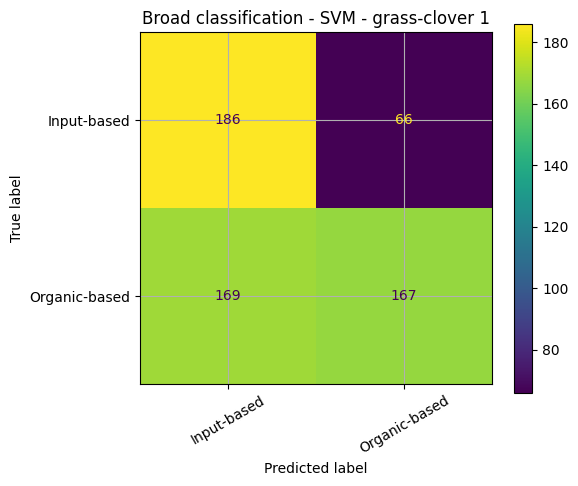

In [ ]:
# ------------------------------------------------------------
# 20. Plot confusion matrix for best broad SVM crop
# ------------------------------------------------------------

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

if len(broad_svm_results) > 0:
    best_crop = broad_svm_results.sort_values(
        "balanced_accuracy", ascending=False
    ).iloc[0]["crop"]

    print("Best crop:", best_crop)

    y_true = broad_svm_pred[best_crop]["y_true"]
    y_pred = broad_svm_pred[best_crop]["y_pred"]
    labels = broad_svm_pred[best_crop]["labels"]

    cm = confusion_matrix(y_true, y_pred, labels=labels)

    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
    fig, ax = plt.subplots(figsize=(6, 5))
    disp.plot(ax=ax, xticks_rotation=30)
    plt.title(f"Broad classification - SVM - {best_crop}")
    plt.tight_layout()
    plt.show()
else:
    print("No broad SVM results available.")

In [ ]:
# ------------------------------------------------------------
# 21. Create summary tables for manuscript
# ------------------------------------------------------------

kruskal_pivot = kruskal_crop_window.pivot_table(
    index="crop",
    columns="vegetation_index",
    values="p_value",
    aggfunc="first"
)

print("Kruskal active crop-window p-value table:")
display(kruskal_pivot)

broad_summary = broad_svm_results[[
    "crop", "n_records", "n_plots", "accuracy", "balanced_accuracy"
]].copy()

broad_summary["accuracy"] = broad_summary["accuracy"] * 100
broad_summary["balanced_accuracy"] = broad_summary["balanced_accuracy"] * 100

print("\nBroad SVM summary table:")
display(broad_summary.sort_values("balanced_accuracy", ascending=False))

Kruskal active crop-window p-value table:


vegetation_index,GNDVI_mean,MSAVI_mean,NDVI_mean,SAVI_mean
crop,,,,
grass-clover 1,0.023239,0.016035,0.025777,0.017700
grass-clover 2,0.000239,0.000245,0.000395,0.000217
potatoes,0.027893,0.045329,0.026308,0.042737
soybeans,0.128660,0.085769,0.046999,0.070250
winter wheat 1,0.000717,0.003830,0.001089,0.003414
winter wheat 2,0.019572,0.037628,0.029272,0.037348



Broad SVM summary table:


,crop,n_records,n_plots,accuracy,balanced_accuracy
0,grass-clover 1,588,28,60.034014,61.755952
4,winter wheat 1,560,56,55.178571,49.843750
1,grass-clover 2,308,28,46.103896,45.359848
5,winter wheat 2,392,56,50.000000,44.940476
2,potatoes,616,56,47.402597,42.092803
3,soybeans,288,28,46.875000,40.909091


In [ ]:
# ------------------------------------------------------------
# 22. Save manuscript summary tables
# ------------------------------------------------------------

kruskal_pivot.to_csv("table_kruskal_active_crop_window_pvalues.csv", index=True)
broad_summary.to_csv("table_broad_svm_summary.csv", index=False)

print("Saved:")
print("table_kruskal_active_crop_window_pvalues.csv")
print("table_broad_svm_summary.csv")

Saved:
table_kruskal_active_crop_window_pvalues.csv
table_broad_svm_summary.csv


Lets correct the low accuract

In [ ]:
# ------------------------------------------------------------
# 21. Build crop-period temporal feature table
# ------------------------------------------------------------

base = df_crop.copy()

# Use only the VI mean columns currently selected
agg_vi_cols = vi_mean_cols.copy()

agg_dict = {}

for col in agg_vi_cols:
    agg_dict[col] = ["mean", "std", "min", "max"]

if "valid_pixels" in base.columns:
    agg_dict["valid_pixels"] = ["mean", "min"]

temporal_features = base.groupby(
    ["plot_id", "BIO", "treatment_class", "broad_class", "crop", "year"],
    dropna=False
).agg(agg_dict)

temporal_features.columns = [
    "_".join(col).strip() for col in temporal_features.columns.values
]

temporal_features = temporal_features.reset_index()

# Number of acquisition dates per plot-crop-year
n_dates = base.groupby(
    ["plot_id", "BIO", "crop", "year"]
)["date"].nunique().reset_index(name="n_dates")

temporal_features = temporal_features.merge(
    n_dates,
    on=["plot_id", "BIO", "crop", "year"],
    how="left"
)

# Add range features
for col in agg_vi_cols:
    temporal_features[f"{col}_range"] = (
        temporal_features[f"{col}_max"] - temporal_features[f"{col}_min"]
    )

print("Temporal feature table shape:", temporal_features.shape)

print("\nRecords by crop:")
print(temporal_features["crop"].value_counts())

print("\nBroad classes:")
print(temporal_features["broad_class"].value_counts(dropna=False))

display(temporal_features.head())

Temporal feature table shape: (288, 29)

Records by crop:
crop
potatoes          64
winter wheat 1    64
winter wheat 2    64
soybeans          32
grass-clover 1    32
grass-clover 2    32
Name: count, dtype: int64

Broad classes:
broad_class
Organic-based    144
Input-based      108
NaN               36
Name: count, dtype: int64


,plot_id,BIO,treatment_class,broad_class,crop,year,NDVI_mean_mean,NDVI_mean_std,NDVI_mean_min,NDVI_mean_max,...,MSAVI_mean_std,MSAVI_mean_min,MSAVI_mean_max,valid_pixels_mean,valid_pixels_min,n_dates,NDVI_mean_range,GNDVI_mean_range,SAVI_mean_range,MSAVI_mean_range
0,1,N,Unfertilised control,NaN,potatoes,2018,0.277639,0.087347,0.134055,0.437648,...,0.106933,0.135804,0.500054,18.0,18,13,0.303593,0.248703,0.364754,0.364249
1,1,N,Unfertilised control,NaN,winter wheat 1,2017,0.340365,0.042692,0.293776,0.411286,...,0.054204,0.271801,0.437075,18.0,18,7,0.117510,0.102977,0.158989,0.165273
2,1,N,Unfertilised control,NaN,winter wheat 2,2019,0.342847,0.095291,0.203458,0.457928,...,0.101245,0.224674,0.508554,18.0,18,6,0.254469,0.200840,0.289891,0.283881
3,2,M,Mineral conventional,Input-based,potatoes,2018,0.270586,0.113545,0.091996,0.463139,...,0.132443,0.094794,0.525145,20.0,20,13,0.371143,0.298845,0.433682,0.430351
4,2,M,Mineral conventional,Input-based,winter wheat 1,2017,0.327272,0.045345,0.266267,0.412784,...,0.054976,0.276726,0.436544,20.0,20,7,0.146517,0.112712,0.160132,0.159818


In [ ]:
# ------------------------------------------------------------
# 23. Prepare temporal feature columns
# ------------------------------------------------------------

temporal_feature_cols = [
    c for c in temporal_features.columns
    if any(vi in c for vi in ["NDVI", "GNDVI", "SAVI", "MSAVI", "EVI"])
]

# Exclude EVI if you excluded it earlier
temporal_feature_cols = [c for c in temporal_feature_cols if "EVI" not in c]

if "n_dates" in temporal_features.columns:
    temporal_feature_cols.append("n_dates")

if "valid_pixels_mean" in temporal_features.columns:
    temporal_feature_cols.append("valid_pixels_mean")

if "valid_pixels_min" in temporal_features.columns:
    temporal_feature_cols.append("valid_pixels_min")

print("Temporal feature columns:")
print(temporal_feature_cols)

temporal_ml = temporal_features.dropna(
    subset=temporal_feature_cols + ["plot_id", "crop", "broad_class"]
).copy()

print("Temporal ML shape:", temporal_ml.shape)
display(temporal_ml.head())

Temporal feature columns:
['NDVI_mean_mean', 'NDVI_mean_std', 'NDVI_mean_min', 'NDVI_mean_max', 'GNDVI_mean_mean', 'GNDVI_mean_std', 'GNDVI_mean_min', 'GNDVI_mean_max', 'SAVI_mean_mean', 'SAVI_mean_std', 'SAVI_mean_min', 'SAVI_mean_max', 'MSAVI_mean_mean', 'MSAVI_mean_std', 'MSAVI_mean_min', 'MSAVI_mean_max', 'NDVI_mean_range', 'GNDVI_mean_range', 'SAVI_mean_range', 'MSAVI_mean_range', 'n_dates', 'valid_pixels_mean', 'valid_pixels_min']
Temporal ML shape: (252, 29)


,plot_id,BIO,treatment_class,broad_class,crop,year,NDVI_mean_mean,NDVI_mean_std,NDVI_mean_min,NDVI_mean_max,...,MSAVI_mean_std,MSAVI_mean_min,MSAVI_mean_max,valid_pixels_mean,valid_pixels_min,n_dates,NDVI_mean_range,GNDVI_mean_range,SAVI_mean_range,MSAVI_mean_range
3,2,M,Mineral conventional,Input-based,potatoes,2018,0.270586,0.113545,0.091996,0.463139,...,0.132443,0.094794,0.525145,20.0,20,13,0.371143,0.298845,0.433682,0.430351
4,2,M,Mineral conventional,Input-based,winter wheat 1,2017,0.327272,0.045345,0.266267,0.412784,...,0.054976,0.276726,0.436544,20.0,20,7,0.146517,0.112712,0.160132,0.159818
5,2,M,Mineral conventional,Input-based,winter wheat 2,2019,0.319594,0.117463,0.147701,0.453568,...,0.123335,0.164352,0.502418,20.0,20,6,0.305867,0.247176,0.343076,0.338066
9,4,M,Mineral conventional,Input-based,potatoes,2019,0.286091,0.092913,0.123864,0.390792,...,0.105913,0.121855,0.425827,20.0,20,8,0.266928,0.208959,0.300179,0.303972
10,4,M,Mineral conventional,Input-based,soybeans,2017,0.261471,0.115361,0.146265,0.478588,...,0.139013,0.116427,0.494412,20.0,20,9,0.332324,0.291671,0.370655,0.377985


In [ ]:
# ------------------------------------------------------------
# 24. Broad SVM classification using crop-period temporal features
# ------------------------------------------------------------

broad_temporal = temporal_ml.dropna(subset=["broad_class"]).copy()

broad_temporal_svm_results, broad_temporal_svm_pred = classify_by_crop(
    broad_temporal,
    target_col="broad_class",
    feature_cols=temporal_feature_cols,
    model_type="svm"
)

print("SVM broad classification using temporal crop-period features:")
display(
    broad_temporal_svm_results.sort_values(
        "balanced_accuracy", ascending=False
    )
)

SVM broad classification using temporal crop-period features:


,crop,target,model,n_records,n_plots,n_classes,accuracy,balanced_accuracy
4,winter wheat 1,broad_class,svm,56,56,2,0.696429,0.666667
2,potatoes,broad_class,svm,56,56,2,0.625000,0.583333
1,grass-clover 2,broad_class,svm,28,28,2,0.607143,0.552083
3,soybeans,broad_class,svm,28,28,2,0.571429,0.531250
5,winter wheat 2,broad_class,svm,56,56,2,0.535714,0.468750
0,grass-clover 1,broad_class,svm,28,28,2,0.464286,0.427083


In [ ]:
# ------------------------------------------------------------
# 25. Broad Random Forest classification using crop-period temporal features
# ------------------------------------------------------------

broad_temporal_rf_results, broad_temporal_rf_pred = classify_by_crop(
    broad_temporal,
    target_col="broad_class",
    feature_cols=temporal_feature_cols,
    model_type="rf"
)

print("Random Forest broad classification using temporal crop-period features:")
display(
    broad_temporal_rf_results.sort_values(
        "balanced_accuracy", ascending=False
    )
)

Random Forest broad classification using temporal crop-period features:


,crop,target,model,n_records,n_plots,n_classes,accuracy,balanced_accuracy
4,winter wheat 1,broad_class,rf,56,56,2,0.660714,0.640625
1,grass-clover 2,broad_class,rf,28,28,2,0.607143,0.583333
2,potatoes,broad_class,rf,56,56,2,0.607143,0.583333
5,winter wheat 2,broad_class,rf,56,56,2,0.500000,0.473958
3,soybeans,broad_class,rf,28,28,2,0.500000,0.458333
0,grass-clover 1,broad_class,rf,28,28,2,0.428571,0.385417


In [ ]:
# ------------------------------------------------------------
# 26. Potato-only broad classification using cultivation period
#     April–September across the 3 potato years
# ------------------------------------------------------------

potato_months = [4, 5, 6, 7, 8, 9]

potato_temporal = ml_df[
    (ml_df["crop"] == "potatoes") &
    (ml_df["month"].isin(potato_months)) &
    (ml_df["broad_class"].notna())
].copy()

print("Potato cultivation-period dataset:")
print("Records:", len(potato_temporal))
print("Plots:", potato_temporal["plot_id"].nunique())
print("Classes:")
print(potato_temporal["broad_class"].value_counts())

potato_temporal_svm_results, potato_temporal_svm_pred = classify_by_crop(
    potato_temporal,
    target_col="broad_class",
    feature_cols=feature_cols,
    model_type="svm"
)

potato_temporal_rf_results, potato_temporal_rf_pred = classify_by_crop(
    potato_temporal,
    target_col="broad_class",
    feature_cols=feature_cols,
    model_type="rf"
)

print("\nSVM potato classification using April–September:")
display(
    potato_temporal_svm_results.sort_values(
        "balanced_accuracy", ascending=False
    )
)

print("\nRandom Forest potato classification using April–September:")
display(
    potato_temporal_rf_results.sort_values(
        "balanced_accuracy", ascending=False
    )
)

Potato cultivation-period dataset:
Records: 616
Plots: 56
Classes:
broad_class
Organic-based    352
Input-based      264
Name: count, dtype: int64

SVM potato classification using April–September:


,crop,target,model,n_records,n_plots,n_classes,accuracy,balanced_accuracy
0,potatoes,broad_class,svm,616,56,2,0.474026,0.420928



Random Forest potato classification using April–September:


,crop,target,model,n_records,n_plots,n_classes,accuracy,balanced_accuracy
0,potatoes,broad_class,rf,616,56,2,0.475649,0.454545


In [ ]:
# ------------------------------------------------------------
# 27. Potato-only broad classification by year using aggregated
#     April–September temporal features per plot
# ------------------------------------------------------------

potato_months = [4, 5, 6, 7, 8, 9]

# IMPORTANT:
# Use df, not ml_df, because ml_df may already be filtered by an older crop window.
potato_period = df[
    (df["crop"] == "potatoes") &
    (df["month"].isin(potato_months)) &
    (df["broad_class"].notna())
].copy()

# Use selected VI features
vi_cols = feature_cols.copy()

# Remove columns that may not exist in df
vi_cols = [c for c in vi_cols if c in potato_period.columns]

print("Potato April–September records:", len(potato_period))
print("Years available:", sorted(potato_period["year"].unique()))
print("Feature columns:")
print(vi_cols)

agg_dict = {}

for col in vi_cols:
    agg_dict[col] = ["mean", "median", "std", "min", "max"]

# ------------------------------------------------------------
# 26A. Helper function for one-year potato aggregation/classification
# ------------------------------------------------------------

def run_potato_year_analysis(potato_period, yr, agg_dict, vi_cols):

    potato_year_df = potato_period[
        potato_period["year"] == yr
    ].copy()

    print("\n" + "#"*70)
    print(f"STARTING POTATO ANALYSIS FOR YEAR {yr}")
    print("#"*70)

    print("Raw potato records for year:", len(potato_year_df))
    print("Unique dates:")
    print(sorted(potato_year_df["date"].dt.strftime("%Y-%m-%d").unique()))

    if potato_year_df.empty:
        print(f"No potato records available for {yr}.")
        return None, None, None

    potato_year_agg = (
        potato_year_df
        .groupby(["plot_id", "crop", "broad_class"])
        .agg(agg_dict)
    )

    potato_year_agg.columns = [
        f"{var}_{stat}" for var, stat in potato_year_agg.columns
    ]

    potato_year_agg = potato_year_agg.reset_index()

    # Add number of dates per plot
    n_dates = (
        potato_year_df
        .groupby("plot_id")["date"]
        .nunique()
        .reset_index(name="n_dates")
    )

    potato_year_agg = potato_year_agg.merge(
        n_dates,
        on="plot_id",
        how="left"
    )

    # Add range features
    for col in vi_cols:
        if f"{col}_max" in potato_year_agg.columns and f"{col}_min" in potato_year_agg.columns:
            potato_year_agg[f"{col}_range"] = (
                potato_year_agg[f"{col}_max"] - potato_year_agg[f"{col}_min"]
            )

    print("\n" + "="*70)
    print(f"Aggregated potato April–September features for year: {yr}")
    print("="*70)
    print("Records:", len(potato_year_agg))
    print("Plots:", potato_year_agg["plot_id"].nunique())
    print("Classes:")
    print(potato_year_agg["broad_class"].value_counts())
    print("Dates per plot:")
    print(potato_year_agg["n_dates"].describe())

    if potato_year_agg["broad_class"].nunique() < 2:
        print("Skipped: only one class available.")
        return potato_year_agg, None, None

    potato_agg_feature_cols = [
        c for c in potato_year_agg.columns
        if c not in ["plot_id", "crop", "broad_class"]
    ]

    # Remove columns with all NaN
    potato_agg_feature_cols = [
        c for c in potato_agg_feature_cols
        if not potato_year_agg[c].isna().all()
    ]

    # Fill remaining NaN values, usually std from limited observations
    potato_year_agg[potato_agg_feature_cols] = potato_year_agg[potato_agg_feature_cols].fillna(0)

    svm_results, svm_pred = classify_by_crop(
        potato_year_agg,
        target_col="broad_class",
        feature_cols=potato_agg_feature_cols,
        model_type="svm"
    )

    rf_results, rf_pred = classify_by_crop(
        potato_year_agg,
        target_col="broad_class",
        feature_cols=potato_agg_feature_cols,
        model_type="rf"
    )

    svm_results = svm_results.copy()
    rf_results = rf_results.copy()

    svm_results["year"] = yr
    rf_results["year"] = yr

    print("\nSVM aggregated results:")
    display(svm_results)

    print("\nRandom Forest aggregated results:")
    display(rf_results)

    combined_results = pd.concat([svm_results, rf_results], ignore_index=True)

    return potato_year_agg, combined_results, {
        "svm_pred": svm_pred,
        "rf_pred": rf_pred,
        "feature_cols": potato_agg_feature_cols
    }


# ------------------------------------------------------------
# 28. Run 2017 separately
# ------------------------------------------------------------

potato_2017_agg, potato_2017_results, potato_2017_predictions = run_potato_year_analysis(
    potato_period=potato_period,
    yr=2017,
    agg_dict=agg_dict,
    vi_cols=vi_cols
)

print("\n" + "#"*70)
print("SEPARATE SUMMARY FOR POTATO 2017")
print("#"*70)

if potato_2017_results is not None:
    display(
        potato_2017_results[
            ["year", "crop", "target", "model", "n_records", "n_plots",
             "n_classes", "accuracy", "balanced_accuracy"]
        ].sort_values("balanced_accuracy", ascending=False)
    )
else:
    print("No valid 2017 potato classification results.")


# ------------------------------------------------------------
# 29. Run all potato years and collect results
# ------------------------------------------------------------

potato_year_agg_results = []

for yr in sorted(potato_period["year"].unique()):

    potato_year_agg, year_results, year_predictions = run_potato_year_analysis(
        potato_period=potato_period,
        yr=yr,
        agg_dict=agg_dict,
        vi_cols=vi_cols
    )

    if year_results is not None:
        potato_year_agg_results.append(year_results)

potato_year_agg_results_df = pd.concat(
    potato_year_agg_results,
    ignore_index=True
)

print("\nSummary: Aggregated potato April–September by year")
display(
    potato_year_agg_results_df[
        ["year", "crop", "target", "model", "n_records", "n_plots",
         "n_classes", "accuracy", "balanced_accuracy"]
    ].sort_values(["year", "balanced_accuracy"], ascending=[True, False])
)

Potato April–September records: 728
Years available: [np.int64(2018), np.int64(2019)]
Feature columns:
['NDVI_mean', 'GNDVI_mean', 'SAVI_mean', 'MSAVI_mean', 'NDVI_std', 'GNDVI_std', 'SAVI_std', 'MSAVI_std', 'valid_pixels']

######################################################################
STARTING POTATO ANALYSIS FOR YEAR 2017
######################################################################
Raw potato records for year: 0
Unique dates:
[]
No potato records available for 2017.

######################################################################
SEPARATE SUMMARY FOR POTATO 2017
######################################################################
No valid 2017 potato classification results.

######################################################################
STARTING POTATO ANALYSIS FOR YEAR 2018
######################################################################
Raw potato records for year: 448
Unique dates:
['2018-04-06', '2018-04-19', '2018-04-29', '2018-05-08', '

,crop,target,model,n_records,n_plots,n_classes,accuracy,balanced_accuracy,year
0,potatoes,broad_class,svm,28,28,2,0.571429,0.53125,2018



Random Forest aggregated results:


,crop,target,model,n_records,n_plots,n_classes,accuracy,balanced_accuracy,year
0,potatoes,broad_class,rf,28,28,2,0.75,0.729167,2018



######################################################################
STARTING POTATO ANALYSIS FOR YEAR 2019
######################################################################
Raw potato records for year: 280
Unique dates:
['2019-04-19', '2019-05-31', '2019-06-08', '2019-06-27', '2019-07-23', '2019-08-09', '2019-08-26', '2019-09-12', '2019-09-21']

Aggregated potato April–September features for year: 2019
Records: 28
Plots: 28
Classes:
broad_class
Organic-based    16
Input-based      12
Name: count, dtype: int64
Dates per plot:
count    28.0
mean      9.0
std       0.0
min       9.0
25%       9.0
50%       9.0
75%       9.0
max       9.0
Name: n_dates, dtype: float64

SVM aggregated results:


,crop,target,model,n_records,n_plots,n_classes,accuracy,balanced_accuracy,year
0,potatoes,broad_class,svm,28,28,2,0.678571,0.645833,2019



Random Forest aggregated results:


,crop,target,model,n_records,n_plots,n_classes,accuracy,balanced_accuracy,year
0,potatoes,broad_class,rf,28,28,2,0.678571,0.645833,2019



Summary: Aggregated potato April–September by year


,year,crop,target,model,n_records,n_plots,n_classes,accuracy,balanced_accuracy
1,2018,potatoes,broad_class,rf,28,28,2,0.750000,0.729167
0,2018,potatoes,broad_class,svm,28,28,2,0.571429,0.531250
2,2019,potatoes,broad_class,svm,28,28,2,0.678571,0.645833
3,2019,potatoes,broad_class,rf,28,28,2,0.678571,0.645833


In [ ]:
# ------------------------------------------------------------
# 30. Potato April–September monthly feature classification
# ------------------------------------------------------------

potato_months = [4, 5, 6, 7, 8, 9]

potato_period = df[
    (df["crop"] == "potatoes") &
    (df["month"].isin(potato_months)) &
    (df["broad_class"].notna())
].copy()

vi_cols = [c for c in feature_cols if c in potato_period.columns]

print("VI columns used:")
print(vi_cols)

potato_monthly_results = []

for yr in sorted(potato_period["year"].unique()):

    potato_year = potato_period[potato_period["year"] == yr].copy()

    print("\n" + "="*70)
    print(f"Potato monthly features for year {yr}")
    print("="*70)

    # Aggregate per plot, broad class, month
    monthly = (
        potato_year
        .groupby(["plot_id", "broad_class", "month"])[vi_cols]
        .mean()
        .reset_index()
    )

    # Pivot months into columns
    monthly_wide = monthly.pivot_table(
        index=["plot_id", "broad_class"],
        columns="month",
        values=vi_cols
    )

    monthly_wide.columns = [
        f"{var}_m{month}" for var, month in monthly_wide.columns
    ]

    monthly_wide = monthly_wide.reset_index()

    # Add n_dates per plot
    n_dates = (
        potato_year
        .groupby("plot_id")["date"]
        .nunique()
        .reset_index(name="n_dates")
    )

    monthly_wide = monthly_wide.merge(n_dates, on="plot_id", how="left")

    # Fill missing monthly values with column median
    feature_monthly_cols = [
        c for c in monthly_wide.columns
        if c not in ["plot_id", "broad_class"]
    ]

    for c in feature_monthly_cols:
        monthly_wide[c] = monthly_wide[c].fillna(monthly_wide[c].median())

    # Add crop name because classify_by_crop expects it
    monthly_wide["crop"] = "potatoes"

    print("Records:", len(monthly_wide))
    print("Classes:")
    print(monthly_wide["broad_class"].value_counts())
    print("Feature count:", len(feature_monthly_cols))

    svm_res, svm_pred = classify_by_crop(
        monthly_wide,
        target_col="broad_class",
        feature_cols=feature_monthly_cols,
        model_type="svm"
    )

    rf_res, rf_pred = classify_by_crop(
        monthly_wide,
        target_col="broad_class",
        feature_cols=feature_monthly_cols,
        model_type="rf"
    )

    svm_res["year"] = yr
    rf_res["year"] = yr

    potato_monthly_results.append(svm_res)
    potato_monthly_results.append(rf_res)

    print("\nSVM monthly results:")
    display(svm_res)

    print("\nRF monthly results:")
    display(rf_res)

potato_monthly_results_df = pd.concat(potato_monthly_results, ignore_index=True)

print("\nSummary: potato monthly features")
display(
    potato_monthly_results_df[
        ["year", "crop", "model", "n_records", "n_plots",
         "accuracy", "balanced_accuracy"]
    ].sort_values(["year", "balanced_accuracy"], ascending=[True, False])
)

VI columns used:
['NDVI_mean', 'GNDVI_mean', 'SAVI_mean', 'MSAVI_mean', 'NDVI_std', 'GNDVI_std', 'SAVI_std', 'MSAVI_std', 'valid_pixels']

Potato monthly features for year 2018
Records: 28
Classes:
broad_class
Organic-based    16
Input-based      12
Name: count, dtype: int64
Feature count: 55

SVM monthly results:


,crop,target,model,n_records,n_plots,n_classes,accuracy,balanced_accuracy,year
0,potatoes,broad_class,svm,28,28,2,0.714286,0.6875,2018



RF monthly results:


,crop,target,model,n_records,n_plots,n_classes,accuracy,balanced_accuracy,year
0,potatoes,broad_class,rf,28,28,2,0.714286,0.697917,2018



Potato monthly features for year 2019
Records: 28
Classes:
broad_class
Organic-based    16
Input-based      12
Name: count, dtype: int64
Feature count: 55

SVM monthly results:


,crop,target,model,n_records,n_plots,n_classes,accuracy,balanced_accuracy,year
0,potatoes,broad_class,svm,28,28,2,0.678571,0.645833,2019



RF monthly results:


,crop,target,model,n_records,n_plots,n_classes,accuracy,balanced_accuracy,year
0,potatoes,broad_class,rf,28,28,2,0.642857,0.625,2019



Summary: potato monthly features


,year,crop,model,n_records,n_plots,accuracy,balanced_accuracy
1,2018,potatoes,rf,28,28,0.714286,0.697917
0,2018,potatoes,svm,28,28,0.714286,0.687500
2,2019,potatoes,svm,28,28,0.678571,0.645833
3,2019,potatoes,rf,28,28,0.642857,0.625000


In [ ]:
# ------------------------------------------------------------
# 31. Potato broad classification: compare three cultivation windows
#     1. April–September: full cultivation window
#     2. May–August: main canopy development window
#     3. June–August: peak crop signal window
# ------------------------------------------------------------

potato_windows = {
    "April-September_full_cultivation": [4, 5, 6, 7, 8, 9],
    "May-August_main_canopy": [5, 6, 7, 8],
    "June-August_peak_signal": [6, 7, 8],
}

potato_window_results = []

for window_name, months in potato_windows.items():

    print("\n" + "#"*80)
    print(f"WINDOW: {window_name}")
    print(f"MONTHS: {months}")
    print("#"*80)

    potato_period = df[
        (df["crop"] == "potatoes") &
        (df["month"].isin(months)) &
        (df["broad_class"].notna())
    ].copy()

    vi_cols = [c for c in feature_cols if c in potato_period.columns]

    print("Total records:", len(potato_period))
    print("Years available:", sorted(potato_period["year"].unique()))
    print("Feature columns:", vi_cols)

    for yr in sorted(potato_period["year"].unique()):

        potato_year = potato_period[potato_period["year"] == yr].copy()

        print("\n" + "="*70)
        print(f"Year: {yr} | Window: {window_name}")
        print("="*70)

        print("Raw records:", len(potato_year))
        print("Unique dates:", potato_year["date"].nunique())
        print("Dates:")
        print(sorted(potato_year["date"].dt.strftime("%Y-%m-%d").unique()))

        if potato_year.empty:
            print("Skipped: no records.")
            continue

        # Aggregation per plot
        agg_dict = {}
        for col in vi_cols:
            agg_dict[col] = ["mean", "median", "std", "min", "max"]

        potato_agg = (
            potato_year
            .groupby(["plot_id", "crop", "broad_class"])
            .agg(agg_dict)
        )

        potato_agg.columns = [
            f"{var}_{stat}" for var, stat in potato_agg.columns
        ]

        potato_agg = potato_agg.reset_index()

        # Add number of dates per plot
        n_dates = (
            potato_year
            .groupby("plot_id")["date"]
            .nunique()
            .reset_index(name="n_dates")
        )

        potato_agg = potato_agg.merge(
            n_dates,
            on="plot_id",
            how="left"
        )

        # Add range features: max - min
        for col in vi_cols:
            max_col = f"{col}_max"
            min_col = f"{col}_min"

            if max_col in potato_agg.columns and min_col in potato_agg.columns:
                potato_agg[f"{col}_range"] = (
                    potato_agg[max_col] - potato_agg[min_col]
                )

        print("Aggregated records:", len(potato_agg))
        print("Plots:", potato_agg["plot_id"].nunique())
        print("Classes:")
        print(potato_agg["broad_class"].value_counts())
        print("Dates per plot:")
        print(potato_agg["n_dates"].describe())

        if potato_agg["broad_class"].nunique() < 2:
            print("Skipped: only one class.")
            continue

        potato_feature_cols = [
            c for c in potato_agg.columns
            if c not in ["plot_id", "crop", "broad_class"]
        ]

        # Remove all-NaN features
        potato_feature_cols = [
            c for c in potato_feature_cols
            if not potato_agg[c].isna().all()
        ]

        # Fill remaining NaN values, usually std from very few dates
        potato_agg[potato_feature_cols] = (
            potato_agg[potato_feature_cols]
            .fillna(0)
        )

        # SVM
        svm_results, svm_pred = classify_by_crop(
            potato_agg,
            target_col="broad_class",
            feature_cols=potato_feature_cols,
            model_type="svm"
        )

        if len(svm_results) > 0:
            svm_results = svm_results.copy()
            svm_results["year"] = yr
            svm_results["window"] = window_name
            svm_results["months"] = str(months)
            svm_results["n_dates_mean"] = potato_agg["n_dates"].mean()
            potato_window_results.append(svm_results)

            print("\nSVM results:")
            display(svm_results)

        # Random Forest
        rf_results, rf_pred = classify_by_crop(
            potato_agg,
            target_col="broad_class",
            feature_cols=potato_feature_cols,
            model_type="rf"
        )

        if len(rf_results) > 0:
            rf_results = rf_results.copy()
            rf_results["year"] = yr
            rf_results["window"] = window_name
            rf_results["months"] = str(months)
            rf_results["n_dates_mean"] = potato_agg["n_dates"].mean()
            potato_window_results.append(rf_results)

            print("\nRandom Forest results:")
            display(rf_results)


# ------------------------------------------------------------
# 32. Summary table for potato window comparison
# ------------------------------------------------------------

potato_window_results_df = pd.concat(
    potato_window_results,
    ignore_index=True
)

summary_cols = [
    "year", "window", "months", "crop", "model",
    "n_records", "n_plots", "n_classes",
    "n_dates_mean", "accuracy", "balanced_accuracy"
]

print("\n" + "#"*80)
print("SUMMARY: Potato broad classification by cultivation window")
print("#"*80)

display(
    potato_window_results_df[summary_cols]
    .sort_values("balanced_accuracy", ascending=False)
)

# Save results
potato_window_results_df[summary_cols].to_csv(
    "potato_window_comparison_broad_classification.csv",
    index=False
)

print("Saved: potato_window_comparison_broad_classification.csv")


################################################################################
WINDOW: April-September_full_cultivation
MONTHS: [4, 5, 6, 7, 8, 9]
################################################################################
Total records: 728
Years available: [np.int64(2018), np.int64(2019)]
Feature columns: ['NDVI_mean', 'GNDVI_mean', 'SAVI_mean', 'MSAVI_mean', 'NDVI_std', 'GNDVI_std', 'SAVI_std', 'MSAVI_std', 'valid_pixels']

Year: 2018 | Window: April-September_full_cultivation
Raw records: 448
Unique dates: 16
Dates:
['2018-04-06', '2018-04-19', '2018-04-29', '2018-05-08', '2018-05-30', '2018-06-16', '2018-06-20', '2018-06-26', '2018-07-01', '2018-07-19', '2018-07-24', '2018-08-02', '2018-08-03', '2018-08-21', '2018-09-11', '2018-09-25']
Aggregated records: 28
Plots: 28
Classes:
broad_class
Organic-based    16
Input-based      12
Name: count, dtype: int64
Dates per plot:
count    28.0
mean     16.0
std       0.0
min      16.0
25%      16.0
50%      16.0
75%      16.0
max    

,crop,target,model,n_records,n_plots,n_classes,accuracy,balanced_accuracy,year,window,months,n_dates_mean
0,potatoes,broad_class,svm,28,28,2,0.571429,0.53125,2018,April-September_full_cultivation,"[4, 5, 6, 7, 8, 9]",16.0



Random Forest results:


,crop,target,model,n_records,n_plots,n_classes,accuracy,balanced_accuracy,year,window,months,n_dates_mean
0,potatoes,broad_class,rf,28,28,2,0.75,0.729167,2018,April-September_full_cultivation,"[4, 5, 6, 7, 8, 9]",16.0



Year: 2019 | Window: April-September_full_cultivation
Raw records: 280
Unique dates: 9
Dates:
['2019-04-19', '2019-05-31', '2019-06-08', '2019-06-27', '2019-07-23', '2019-08-09', '2019-08-26', '2019-09-12', '2019-09-21']
Aggregated records: 28
Plots: 28
Classes:
broad_class
Organic-based    16
Input-based      12
Name: count, dtype: int64
Dates per plot:
count    28.0
mean      9.0
std       0.0
min       9.0
25%       9.0
50%       9.0
75%       9.0
max       9.0
Name: n_dates, dtype: float64

SVM results:


,crop,target,model,n_records,n_plots,n_classes,accuracy,balanced_accuracy,year,window,months,n_dates_mean
0,potatoes,broad_class,svm,28,28,2,0.678571,0.645833,2019,April-September_full_cultivation,"[4, 5, 6, 7, 8, 9]",9.0


... (17 outputs left out)

,crop,target,model,n_records,n_plots,n_classes,accuracy,balanced_accuracy,year,window,months,n_dates_mean
0,potatoes,broad_class,rf,28,28,2,0.857143,0.854167,2019,June-August_peak_signal,"[6, 7, 8]",5.0



################################################################################
SUMMARY: Potato broad classification by cultivation window
################################################################################


,year,window,months,crop,model,n_records,n_plots,n_classes,n_dates_mean,accuracy,balanced_accuracy
10,2019,June-August_peak_signal,"[6, 7, 8]",potatoes,svm,28,28,2,5.0,0.892857,0.885417
11,2019,June-August_peak_signal,"[6, 7, 8]",potatoes,rf,28,28,2,5.0,0.857143,0.854167
6,2019,May-August_main_canopy,"[5, 6, 7, 8]",potatoes,svm,28,28,2,6.0,0.785714,0.770833
1,2018,April-September_full_cultivation,"[4, 5, 6, 7, 8, 9]",potatoes,rf,28,28,2,16.0,0.750000,0.729167
9,2018,June-August_peak_signal,"[6, 7, 8]",potatoes,rf,28,28,2,9.0,0.678571,0.656250
7,2019,May-August_main_canopy,"[5, 6, 7, 8]",potatoes,rf,28,28,2,6.0,0.678571,0.656250
2,2019,April-September_full_cultivation,"[4, 5, 6, 7, 8, 9]",potatoes,svm,28,28,2,9.0,0.678571,0.645833
3,2019,April-September_full_cultivation,"[4, 5, 6, 7, 8, 9]",potatoes,rf,28,28,2,9.0,0.678571,0.645833
8,2018,June-August_peak_signal,"[6, 7, 8]",potatoes,svm,28,28,2,9.0,0.642857,0.614583
4,2018,May-August_main_canopy,"[5, 6, 7, 8]",potatoes,svm,28,28,2,11.0,0.642857,0.614583


Saved: potato_window_comparison_broad_classification.csv


Total observations: 5403
Unique dates: 52
Date range: 2017-02-14 to 2019-09-21

Crop distribution:
crop_type
winter wheat 1    1386
potatoes          1184
winter wheat 2    1032
grass-clover 1     768
soybeans           617
grass-clover 2     416
Name: count, dtype: int64

System distribution:
system_class
BIODYNAMIC      1353
CONTROL         1350
ORGANIC         1350
CONVENTIONAL    1350
Name: count, dtype: int64


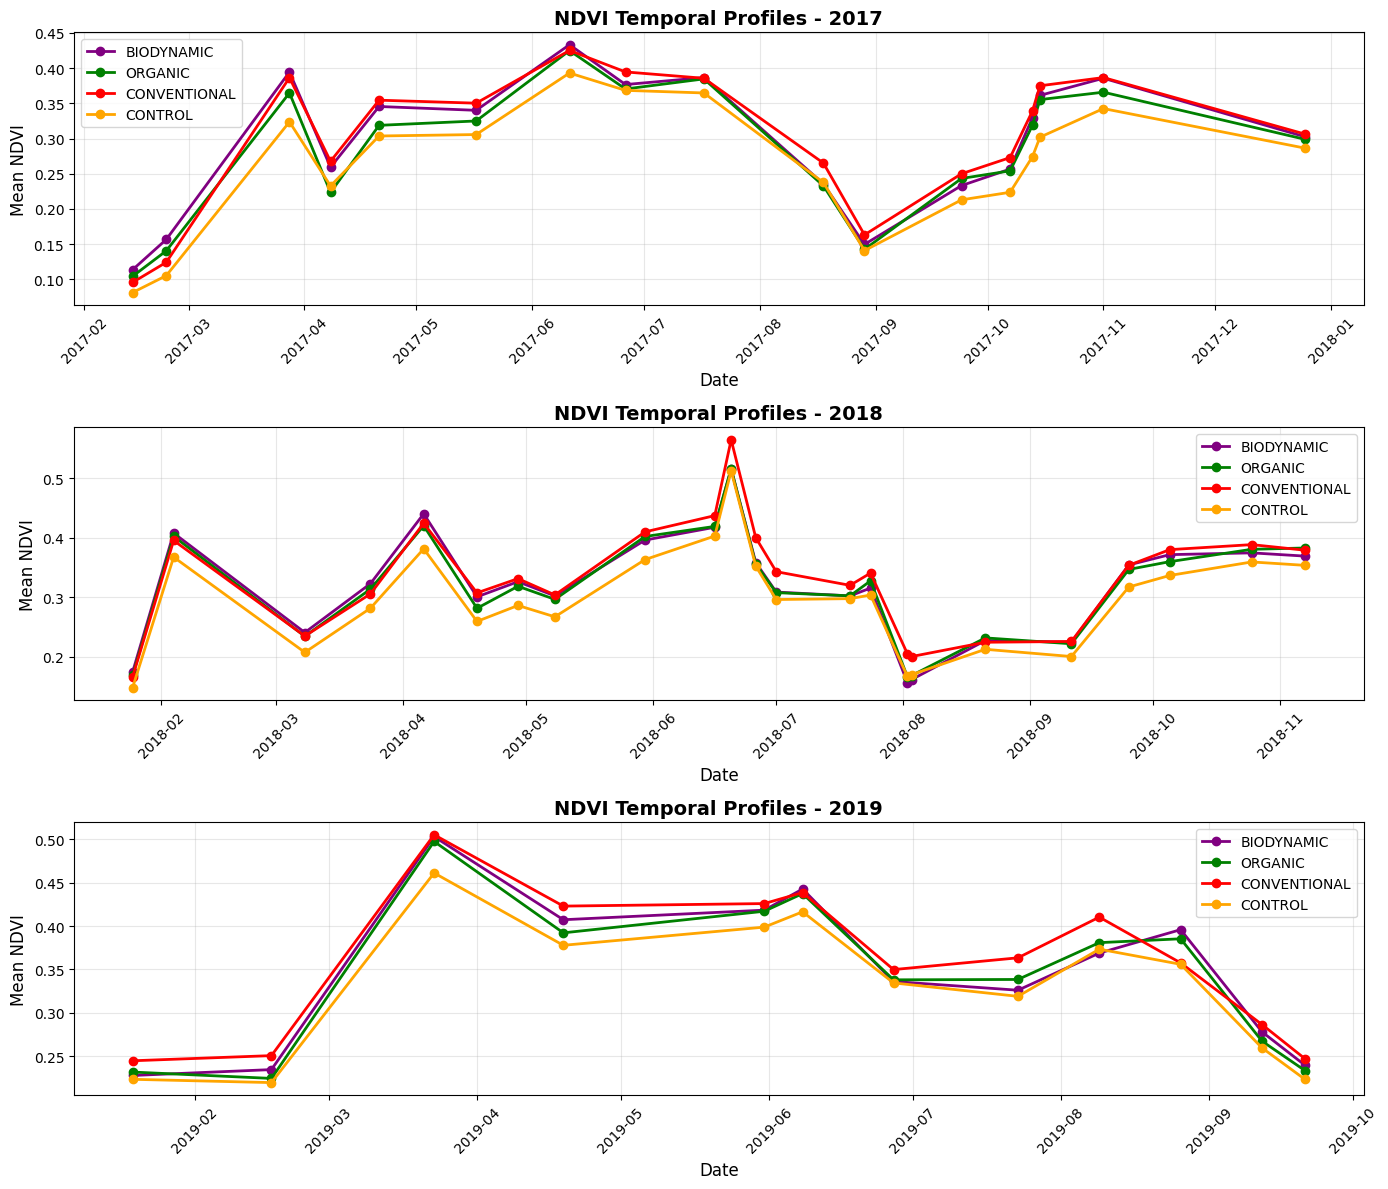

Figure 3 saved: Figure3_Temporal_Profiles.png


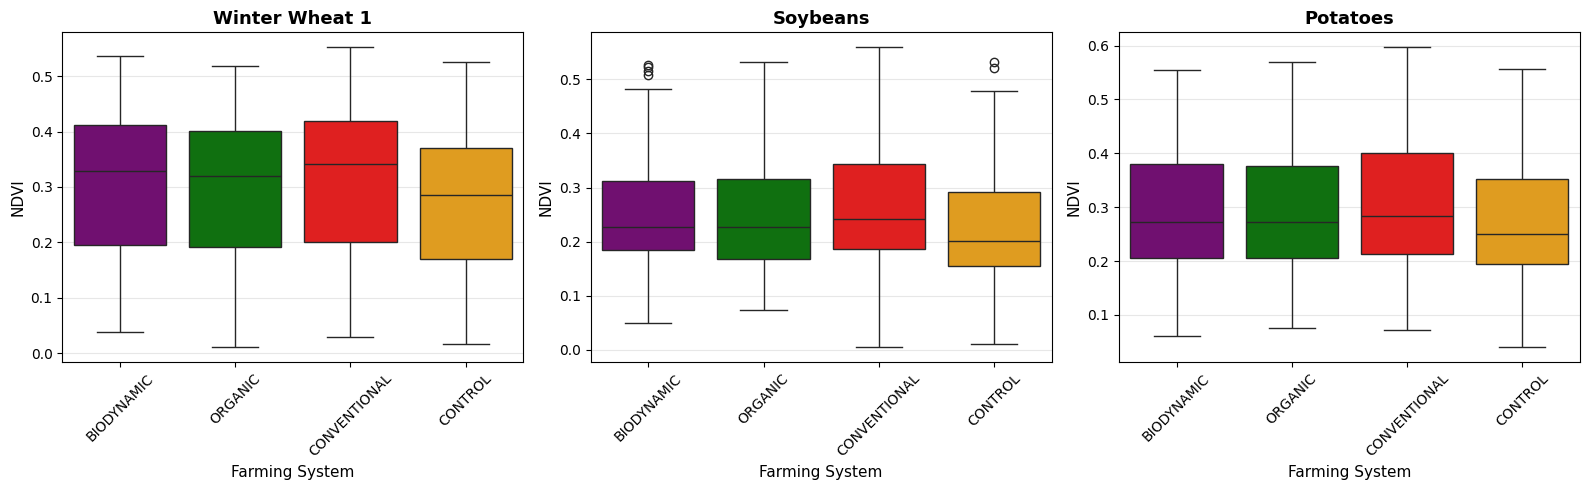

Figure 4 saved: Figure4_Crop_Specific_NDVI.png


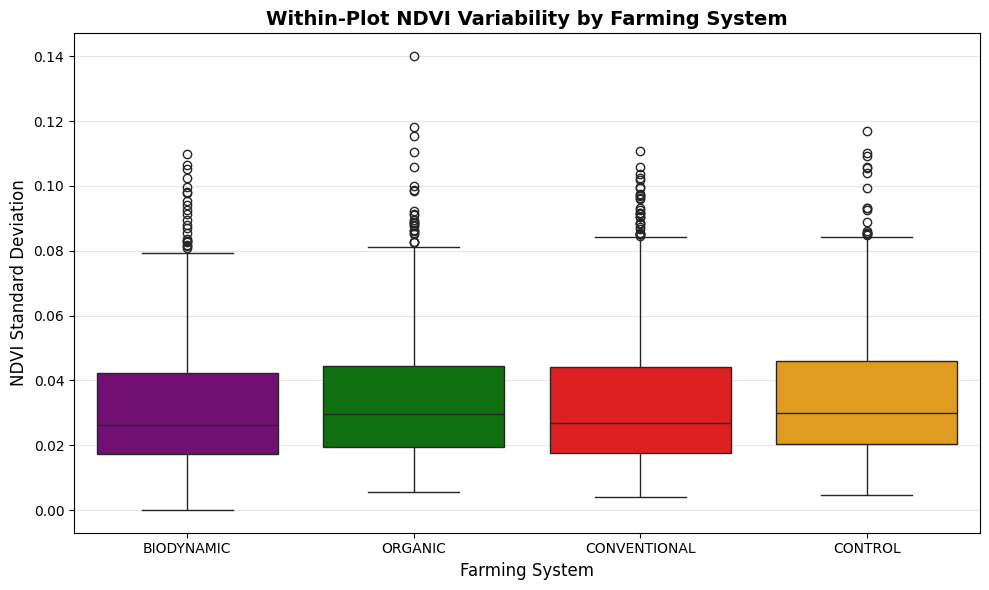


Within-plot heterogeneity statistics:
                  mean       std
system_class                    
BIODYNAMIC    0.031487  0.018945
CONTROL       0.034426  0.018527
CONVENTIONAL  0.032699  0.019962
ORGANIC       0.033852  0.019136

Figure 5 saved: Figure5_Heterogeneity.png
KRUSKAL-WALLIS STATISTICAL TESTS

Top 10 most significant crop-index combinations:
          crop index  H_statistic  p_value significant
winter wheat 1  NDVI    21.961165 0.000066         Yes
winter wheat 1  SAVI    20.460585 0.000136         Yes
winter wheat 1 MSAVI    20.026655 0.000168         Yes
winter wheat 1 GNDVI    19.414230 0.000224         Yes
      soybeans  NDVI    12.733529 0.005250         Yes
grass-clover 1  NDVI    11.307297 0.010175         Yes
grass-clover 1 GNDVI    11.292602 0.010244         Yes
grass-clover 2 GNDVI    11.179594 0.010793         Yes
grass-clover 2  SAVI    11.172913 0.010827         Yes
      soybeans  SAVI    11.098976 0.011203         Yes

Full results saved: Kruskal_Wal

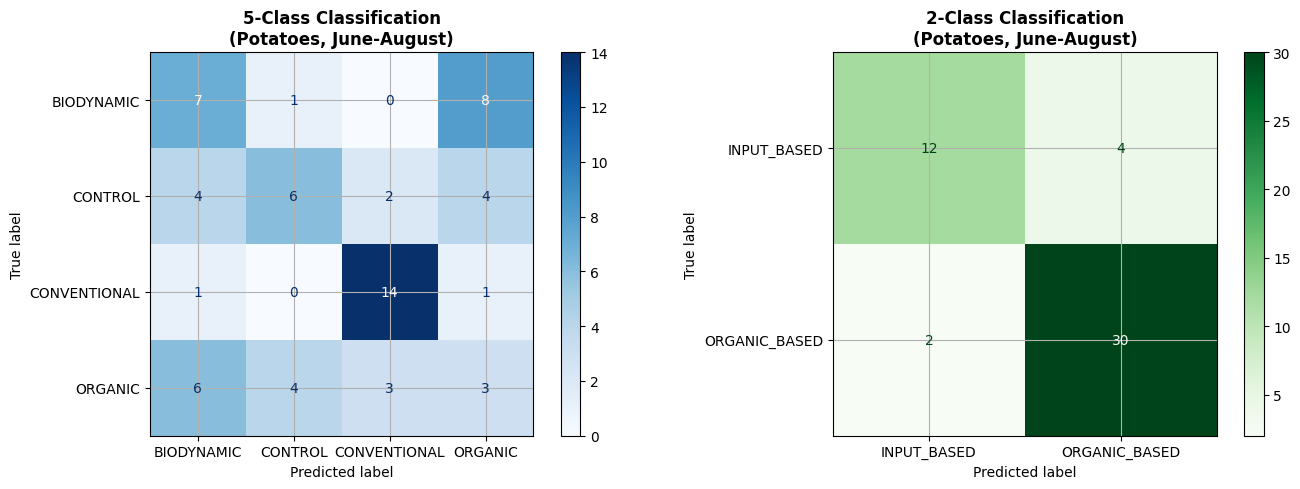


5-class balanced accuracy: 0.469
2-class balanced accuracy: 0.844

Figure 6 saved: Figure6_Confusion_Matrices.png

SUMMARY FOR PAPER

Dataset Summary:
- Total observations: 5403
- Unique dates: 52
- Date range: 2017-02-14 to 2019-09-21
- Number of plots: 96

Best Classification Results (2-class, broad):
          crop  n_plots  n_dates  balanced_accuracy
      potatoes       48       28           0.937500
      soybeans       24       10           0.812500
winter wheat 1       48       28           0.750000
winter wheat 2       48       20           0.640625
grass-clover 2       24       10           0.593750
grass-clover 1       24       18           0.500000

Top 3 Crops by Separability:
             crop  balanced_accuracy
3        potatoes             0.9375
2        soybeans             0.8125
0  winter wheat 1             0.7500

ALL ANALYSIS COMPLETE!

Generated files:
- Figure3_Temporal_Profiles.png
- Figure4_Crop_Specific_NDVI.png
- Figure5_Heterogeneity.png
- Figure6_Confusi

In [ ]:
# ============================================================
# 33. ADDITIONAL ANALYSIS FOR PAPER - Add these cells to your notebook
# ============================================================

# ------------------------------------------------------------
# CELL: Load data and basic cleaning
# ------------------------------------------------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kruskal
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Load your data (adjust path as needed)
df = pd.read_csv('/content/FIBL_PlanetScope_2017_2019_WITH_CROPS.csv')

# Convert date to datetime
df['date'] = pd.to_datetime(df['image_date'])
df['month'] = df['date'].dt.month
df['year'] = df['image_year'].astype(int)

# Create broad 2-class grouping
df['broad_class'] = df['system_class'].replace({
    'ORGANIC': 'ORGANIC_BASED',
    'BIODYNAMIC': 'ORGANIC_BASED',
    'CONVENTIONAL': 'INPUT_BASED'
})

print(f"Total observations: {len(df)}")
print(f"Unique dates: {df['image_date'].nunique()}")
print(f"Date range: {df['image_date'].min()} to {df['image_date'].max()}")
print(f"\nCrop distribution:\n{df['crop_type'].value_counts()}")
print(f"\nSystem distribution:\n{df['system_class'].value_counts()}")

# ------------------------------------------------------------
# CELL: FIGURE 3 - Temporal Profiles by System
# ------------------------------------------------------------
fig, axes = plt.subplots(3, 1, figsize=(14, 12))

for i, year in enumerate([2017, 2018, 2019]):
    year_data = df[df['year'] == year]

    # Group by date and system, calculate mean NDVI
    for system in ['BIODYNAMIC', 'ORGANIC', 'CONVENTIONAL', 'CONTROL']:
        system_data = year_data[year_data['system_class'] == system]
        temporal = system_data.groupby('image_date')['NDVI_mean'].mean().reset_index()
        temporal['date'] = pd.to_datetime(temporal['image_date'])
        temporal = temporal.sort_values('date')

        color_map = {
            'BIODYNAMIC': 'purple',
            'ORGANIC': 'green',
            'CONVENTIONAL': 'red',
            'CONTROL': 'orange'
        }

        axes[i].plot(temporal['date'], temporal['NDVI_mean'],
                    label=system, marker='o', linewidth=2,
                    color=color_map[system], markersize=6)

    axes[i].set_title(f'NDVI Temporal Profiles - {year}', fontsize=14, fontweight='bold')
    axes[i].set_xlabel('Date', fontsize=12)
    axes[i].set_ylabel('Mean NDVI', fontsize=12)
    axes[i].legend(fontsize=10)
    axes[i].grid(True, alpha=0.3)
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('Figure3_Temporal_Profiles.png', dpi=300, bbox_inches='tight')
plt.show()

print("Figure 3 saved: Figure3_Temporal_Profiles.png")

# ------------------------------------------------------------
# CELL: FIGURE 4 - Crop-Specific NDVI Box Plots
# ------------------------------------------------------------
# Select top 3 crops based on your paper
top_crops = ['winter wheat 1', 'soybeans', 'potatoes']

# Create figure
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, crop in enumerate(top_crops):
    crop_data = df[df['crop_type'] == crop]

    # Box plot
    systems_order = ['BIODYNAMIC', 'ORGANIC', 'CONVENTIONAL', 'CONTROL']
    crop_data_filtered = crop_data[crop_data['system_class'].isin(systems_order)]

    sns.boxplot(data=crop_data_filtered, x='system_class', y='NDVI_mean',
                order=systems_order, ax=axes[i],
                palette={'BIODYNAMIC': 'purple', 'ORGANIC': 'green',
                        'CONVENTIONAL': 'red', 'CONTROL': 'orange'})

    axes[i].set_title(f'{crop.title()}', fontsize=13, fontweight='bold')
    axes[i].set_xlabel('Farming System', fontsize=11)
    axes[i].set_ylabel('NDVI', fontsize=11)
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('Figure4_Crop_Specific_NDVI.png', dpi=300, bbox_inches='tight')
plt.show()

print("Figure 4 saved: Figure4_Crop_Specific_NDVI.png")

# ------------------------------------------------------------
# CELL: FIGURE 5 - Within-Plot Heterogeneity
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 6))

systems_order = ['BIODYNAMIC', 'ORGANIC', 'CONVENTIONAL', 'CONTROL']
df_filtered = df[df['system_class'].isin(systems_order)]

sns.boxplot(data=df_filtered, x='system_class', y='NDVI_stdDev',
            order=systems_order, ax=ax,
            palette={'BIODYNAMIC': 'purple', 'ORGANIC': 'green',
                    'CONVENTIONAL': 'red', 'CONTROL': 'orange'})

ax.set_title('Within-Plot NDVI Variability by Farming System',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Farming System', fontsize=12)
ax.set_ylabel('NDVI Standard Deviation', fontsize=12)
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('Figure5_Heterogeneity.png', dpi=300, bbox_inches='tight')
plt.show()

# Calculate means for paper
heterogeneity_stats = df_filtered.groupby('system_class')['NDVI_stdDev'].agg(['mean', 'std'])
print("\nWithin-plot heterogeneity statistics:")
print(heterogeneity_stats)
print("\nFigure 5 saved: Figure5_Heterogeneity.png")

# ------------------------------------------------------------
# CELL: Kruskal-Wallis Tests by Crop
# ------------------------------------------------------------
print("=" * 60)
print("KRUSKAL-WALLIS STATISTICAL TESTS")
print("=" * 60)

# Get unique crops
crops = df['crop_type'].dropna().unique()

kw_results = []

for crop in sorted(crops):
    crop_data = df[df['crop_type'] == crop]

    # Test for each vegetation index
    for vi in ['NDVI', 'GNDVI', 'SAVI', 'MSAVI']:
        col = f'{vi}_mean'
        if col not in crop_data.columns:
            continue

        # Prepare groups
        groups = []
        for system in ['BIODYNAMIC', 'ORGANIC', 'CONVENTIONAL', 'CONTROL']:
            system_data = crop_data[crop_data['system_class'] == system][col].dropna()
            if len(system_data) > 0:
                groups.append(system_data.values)

        if len(groups) >= 2:
            try:
                h_stat, p_val = kruskal(*groups)
                kw_results.append({
                    'crop': crop,
                    'index': vi,
                    'H_statistic': h_stat,
                    'p_value': p_val,
                    'significant': 'Yes' if p_val < 0.05 else 'No'
                })
            except:
                pass

# Create results dataframe
kw_df = pd.DataFrame(kw_results)
kw_df = kw_df.sort_values('p_value')

print("\nTop 10 most significant crop-index combinations:")
print(kw_df.head(10).to_string(index=False))

# Save for paper
kw_df.to_csv('Kruskal_Wallis_Results.csv', index=False)
print("\nFull results saved: Kruskal_Wallis_Results.csv")

# ------------------------------------------------------------
# CELL: Classification - ALL CROPS (5-class)
# ------------------------------------------------------------
print("\n" + "=" * 60)
print("CLASSIFICATION RESULTS - ALL CROPS")
print("=" * 60)

crops_to_analyze = ['winter wheat 1', 'winter wheat 2', 'soybeans',
                    'potatoes', 'grass-clover 1', 'grass-clover 2']

classification_results_5class = []

for crop in crops_to_analyze:
    crop_data = df[df['crop_type'] == crop].copy()

    # Filter to growing season (March-September)
    crop_data = crop_data[crop_data['month'].isin([3,4,5,6,7,8,9])]

    if len(crop_data) < 20:  # Need minimum samples
        continue

    # Pivot to wide format
    features = crop_data.pivot_table(
        index='row_id',
        columns='image_date',
        values='NDVI_mean'
    ).fillna(method='ffill').fillna(method='bfill')

    # Get labels
    labels = crop_data.groupby('row_id')['system_class'].first()

    # Ensure alignment
    features = features.loc[labels.index]

    # Leave-One-Group-Out Cross-Validation
    logo = LeaveOneGroupOut()
    rf = RandomForestClassifier(n_estimators=100, random_state=42)

    y_true, y_pred = [], []
    for train_idx, test_idx in logo.split(features, labels, groups=features.index):
        X_train = features.iloc[train_idx]
        X_test = features.iloc[test_idx]
        y_train = labels.iloc[train_idx]
        y_test = labels.iloc[test_idx]

        rf.fit(X_train, y_train)
        y_pred.append(rf.predict(X_test)[0])
        y_true.append(y_test.iloc[0])

    # Calculate accuracy
    bal_acc = balanced_accuracy_score(y_true, y_pred)

    classification_results_5class.append({
        'crop': crop,
        'n_plots': len(features),
        'n_dates': features.shape[1],
        'balanced_accuracy': bal_acc
    })

    print(f"{crop:20s} | Plots: {len(features):2d} | Dates: {features.shape[1]:2d} | Bal. Acc: {bal_acc:.3f}")

# Save results
results_5class_df = pd.DataFrame(classification_results_5class)
results_5class_df.to_csv('Classification_5class_Results.csv', index=False)

# ------------------------------------------------------------
# CELL: Classification - ALL CROPS (2-class broad)
# ------------------------------------------------------------
print("\n" + "=" * 60)
print("CLASSIFICATION RESULTS - BROAD 2-CLASS (ORGANIC vs INPUT-BASED)")
print("=" * 60)

classification_results_2class = []

for crop in crops_to_analyze:
    crop_data = df[df['crop_type'] == crop].copy()

    # Remove CONTROL for 2-class comparison
    crop_data = crop_data[crop_data['broad_class'].isin(['ORGANIC_BASED', 'INPUT_BASED'])]

    # Filter to growing season
    crop_data = crop_data[crop_data['month'].isin([3,4,5,6,7,8,9])]

    if len(crop_data) < 20:
        continue

    # Pivot to wide format
    features = crop_data.pivot_table(
        index='row_id',
        columns='image_date',
        values='NDVI_mean'
    ).fillna(method='ffill').fillna(method='bfill')

    # Get labels
    labels = crop_data.groupby('row_id')['broad_class'].first()

    # Ensure alignment
    features = features.loc[labels.index]

    # Leave-One-Group-Out Cross-Validation
    logo = LeaveOneGroupOut()
    rf = RandomForestClassifier(n_estimators=100, random_state=42)

    y_true, y_pred = [], []
    for train_idx, test_idx in logo.split(features, labels, groups=features.index):
        X_train = features.iloc[train_idx]
        X_test = features.iloc[test_idx]
        y_train = labels.iloc[train_idx]
        y_test = labels.iloc[test_idx]

        rf.fit(X_train, y_train)
        y_pred.append(rf.predict(X_test)[0])
        y_true.append(y_test.iloc[0])

    # Calculate accuracy
    bal_acc = balanced_accuracy_score(y_true, y_pred)

    classification_results_2class.append({
        'crop': crop,
        'n_plots': len(features),
        'n_dates': features.shape[1],
        'balanced_accuracy': bal_acc
    })

    print(f"{crop:20s} | Plots: {len(features):2d} | Dates: {features.shape[1]:2d} | Bal. Acc: {bal_acc:.3f}")

# Save results
results_2class_df = pd.DataFrame(classification_results_2class)
results_2class_df.to_csv('Classification_2class_Broad_Results.csv', index=False)

# ------------------------------------------------------------
# CELL: FIGURE 6 - Confusion Matrices (for best crop)
# ------------------------------------------------------------
# Use potatoes as the best-performing crop based on your results

crop = 'potatoes'
crop_data = df[df['crop_type'] == crop].copy()
crop_data = crop_data[crop_data['month'].isin([6,7,8])]  # Peak signal window

# 5-CLASS CONFUSION MATRIX
features_5 = crop_data.pivot_table(
    index='row_id',
    columns='image_date',
    values='NDVI_mean'
).fillna(method='ffill').fillna(method='bfill')

labels_5 = crop_data.groupby('row_id')['system_class'].first()
features_5 = features_5.loc[labels_5.index]

# Run classification
logo = LeaveOneGroupOut()
rf = RandomForestClassifier(n_estimators=100, random_state=42)

y_true_5, y_pred_5 = [], []
for train_idx, test_idx in logo.split(features_5, labels_5, groups=features_5.index):
    X_train = features_5.iloc[train_idx]
    X_test = features_5.iloc[test_idx]
    y_train = labels_5.iloc[train_idx]
    y_test = labels_5.iloc[test_idx]

    rf.fit(X_train, y_train)
    y_pred_5.append(rf.predict(X_test)[0])
    y_true_5.append(y_test.iloc[0])

# 2-CLASS CONFUSION MATRIX
crop_data_2 = crop_data[crop_data['broad_class'].isin(['ORGANIC_BASED', 'INPUT_BASED'])]

features_2 = crop_data_2.pivot_table(
    index='row_id',
    columns='image_date',
    values='NDVI_mean'
).fillna(method='ffill').fillna(method='bfill')

labels_2 = crop_data_2.groupby('row_id')['broad_class'].first()
features_2 = features_2.loc[labels_2.index]

y_true_2, y_pred_2 = [], []
for train_idx, test_idx in logo.split(features_2, labels_2, groups=features_2.index):
    X_train = features_2.iloc[train_idx]
    X_test = features_2.iloc[test_idx]
    y_train = labels_2.iloc[train_idx]
    y_test = labels_2.iloc[test_idx]

    rf.fit(X_train, y_train)
    y_pred_2.append(rf.predict(X_test)[0])
    y_true_2.append(y_test.iloc[0])

# PLOT BOTH CONFUSION MATRICES
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 5-class
cm5 = confusion_matrix(y_true_5, y_pred_5)
ConfusionMatrixDisplay(cm5, display_labels=sorted(set(y_true_5))).plot(ax=axes[0], cmap='Blues')
axes[0].set_title('5-Class Classification\n(Potatoes, June-August)', fontweight='bold')

# 2-class
cm2 = confusion_matrix(y_true_2, y_pred_2)
ConfusionMatrixDisplay(cm2, display_labels=sorted(set(y_true_2))).plot(ax=axes[1], cmap='Greens')
axes[1].set_title('2-Class Classification\n(Potatoes, June-August)', fontweight='bold')

plt.tight_layout()
plt.savefig('Figure6_Confusion_Matrices.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"\n5-class balanced accuracy: {balanced_accuracy_score(y_true_5, y_pred_5):.3f}")
print(f"2-class balanced accuracy: {balanced_accuracy_score(y_true_2, y_pred_2):.3f}")
print("\nFigure 6 saved: Figure6_Confusion_Matrices.png")

# ------------------------------------------------------------
# CELL: Summary for Paper
# ------------------------------------------------------------
print("\n" + "=" * 60)
print("SUMMARY FOR PAPER")
print("=" * 60)

print("\nDataset Summary:")
print(f"- Total observations: {len(df)}")
print(f"- Unique dates: {df['image_date'].nunique()}")
print(f"- Date range: {df['image_date'].min()} to {df['image_date'].max()}")
print(f"- Number of plots: {df['row_id'].nunique()}")

print("\nBest Classification Results (2-class, broad):")
print(results_2class_df.sort_values('balanced_accuracy', ascending=False).to_string(index=False))

print("\nTop 3 Crops by Separability:")
print(results_2class_df.nlargest(3, 'balanced_accuracy')[['crop', 'balanced_accuracy']])

print("\n" + "=" * 60)
print("ALL ANALYSIS COMPLETE!")
print("=" * 60)
print("\nGenerated files:")
print("- Figure3_Temporal_Profiles.png")
print("- Figure4_Crop_Specific_NDVI.png")
print("- Figure5_Heterogeneity.png")
print("- Figure6_Confusion_Matrices.png")
print("- Kruskal_Wallis_Results.csv")
print("- Classification_5class_Results.csv")
print("- Classification_2class_Broad_Results.csv")


# REVISED CLASSIFICATION: CROP-SPECIFIC OPTIMAL WINDOWS
## Using agronomically-justified temporal windows per crop

In [ ]:
# ============================================================
# CROP-SPECIFIC TEMPORAL WINDOW CLASSIFICATION
# ============================================================

# Define optimal temporal windows per crop
CROP_WINDOWS = {
    'winter wheat 1': [3, 4, 5, 6, 7],      # Spring through harvest
    'winter wheat 2': [3, 4, 5, 6, 7],      # Same as winter wheat 1
    'soybeans': [5, 6, 7, 8, 9],             # Planting through harvest
    'potatoes': [4, 5, 6, 7, 8, 9],          # Planting through harvest
    'grass-clover 1': [3, 4, 5, 6, 7, 8, 9, 10],  # Perennial active season
    'grass-clover 2': [3, 4, 5, 6, 7, 8, 9, 10]   # Perennial active season
}

classification_results_2class_REVISED = []

for crop in CROP_WINDOWS.keys():
    # Get optimal months for this crop
    optimal_months = CROP_WINDOWS[crop]

    # Filter data
    crop_data = df[df['crop_type'] == crop].copy()
    crop_data = crop_data[crop_data['broad_class'].isin(['ORGANIC_BASED', 'INPUT_BASED'])]
    crop_data = crop_data[crop_data['month'].isin(optimal_months)]  # CROP-SPECIFIC!

    if len(crop_data) < 20:
        continue

    # Pivot to wide format
    features = crop_data.pivot_table(
        index='row_id',
        columns='image_date',
        values='NDVI_mean'
    ).fillna(method='ffill').fillna(method='bfill')

    # Get labels
    labels = crop_data.groupby('row_id')['broad_class'].first()
    features = features.loc[labels.index]

    # Leave-One-Group-Out CV
    logo = LeaveOneGroupOut()
    rf = RandomForestClassifier(n_estimators=100, random_state=42)

    y_true, y_pred = [], []
    for train_idx, test_idx in logo.split(features, labels, groups=features.index):
        X_train = features.iloc[train_idx]
        X_test = features.iloc[test_idx]
        y_train = labels.iloc[train_idx]
        y_test = labels.iloc[test_idx]

        rf.fit(X_train, y_train)
        y_pred.append(rf.predict(X_test)[0])
        y_true.append(y_test.iloc[0])

    # Calculate accuracy
    bal_acc = balanced_accuracy_score(y_true, y_pred)

    classification_results_2class_REVISED.append({
        'crop': crop,
        'optimal_months': str(optimal_months),
        'n_plots': len(features),
        'n_dates': features.shape[1],
        'balanced_accuracy': bal_acc
    })

    print(f"{crop:20s} | Months: {str(optimal_months):25s} | Plots: {len(features):2d} | Dates: {features.shape[1]:2d} | Acc: {bal_acc:.3f}")

# Results dataframe
results_revised_df = pd.DataFrame(classification_results_2class_REVISED)
results_revised_df = results_revised_df.sort_values('balanced_accuracy', ascending=False)

print("\n" + "=" * 70)
print("REVISED RESULTS WITH CROP-SPECIFIC WINDOWS:")
print("=" * 70)
print(results_revised_df.to_string(index=False))

# Save
results_revised_df.to_csv('Classification_2class_CropSpecific_Windows.csv', index=False)

winter wheat 1       | Months: [3, 4, 5, 6, 7]           | Plots: 48 | Dates: 20 | Acc: 0.781
winter wheat 2       | Months: [3, 4, 5, 6, 7]           | Plots: 48 | Dates: 13 | Acc: 0.703
soybeans             | Months: [5, 6, 7, 8, 9]           | Plots: 24 | Dates:  7 | Acc: 0.844
potatoes             | Months: [4, 5, 6, 7, 8, 9]        | Plots: 48 | Dates: 25 | Acc: 0.844
grass-clover 1       | Months: [3, 4, 5, 6, 7, 8, 9, 10] | Plots: 24 | Dates: 20 | Acc: 0.406
grass-clover 2       | Months: [3, 4, 5, 6, 7, 8, 9, 10] | Plots: 24 | Dates: 10 | Acc: 0.594

REVISED RESULTS WITH CROP-SPECIFIC WINDOWS:
          crop            optimal_months  n_plots  n_dates  balanced_accuracy
      potatoes        [4, 5, 6, 7, 8, 9]       48       25           0.843750
      soybeans           [5, 6, 7, 8, 9]       24        7           0.843750
winter wheat 1           [3, 4, 5, 6, 7]       48       20           0.781250
winter wheat 2           [3, 4, 5, 6, 7]       48       13           0.703125
g

In [ ]:
# ============================================================
# FINAL FEATURE COLUMNS AFTER REPAIR
# EVI excluded
# ============================================================

final_vi_cols = [
    "NDVI_mean", "GNDVI_mean", "SAVI_mean", "MSAVI_mean",
    "NDVI_std", "GNDVI_std", "SAVI_std", "MSAVI_std"
]

final_vi_cols = [c for c in final_vi_cols if c in df.columns]

print("Final VI columns used:")
print(final_vi_cols)

Final VI columns used:
['NDVI_mean', 'GNDVI_mean', 'SAVI_mean', 'MSAVI_mean']


In [ ]:
# Check columns containing std / stdDev
std_like_cols = [c for c in df.columns if "std" in c.lower()]
print(std_like_cols)

['NDVI_stdDev', 'GNDVI_stdDev', 'EVI_stdDev', 'SAVI_stdDev', 'MSAVI_stdDev']


In [ ]:
# Copy old stdDev columns into clean std names
std_mapping = {
    "NDVI_stdDev": "NDVI_std",
    "GNDVI_stdDev": "GNDVI_std",
    "SAVI_stdDev": "SAVI_std",
    "MSAVI_stdDev": "MSAVI_std"
}

for old_col, new_col in std_mapping.items():
    if old_col in df.columns:
        df[new_col] = df[old_col]

final_vi_cols = [
    "NDVI_mean", "GNDVI_mean", "SAVI_mean", "MSAVI_mean",
    "NDVI_std", "GNDVI_std", "SAVI_std", "MSAVI_std"
]

final_vi_cols = [c for c in final_vi_cols if c in df.columns]

print("Final VI columns used:")
print(final_vi_cols)

Final VI columns used:
['NDVI_mean', 'GNDVI_mean', 'SAVI_mean', 'MSAVI_mean', 'NDVI_std', 'GNDVI_std', 'SAVI_std', 'MSAVI_std']


In [ ]:
# ============================================================
# 34. All-crop phenological-window comparison
# Creates all_window_results_df
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Ensure 'crop' column exists (if df was reloaded without renaming 'crop_type')
# ------------------------------------------------------------
if "crop_type" in df.columns and "crop" not in df.columns:
    df = df.rename(columns={"crop_type": "crop"})

# ------------------------------------------------------------
# 34A. Final binary grouping: D/O vs K, M and N excluded
# ------------------------------------------------------------

def final_binary_class_from_bio(bio):
    bio = str(bio).upper().strip()

    if bio in ["D1", "D2", "O1", "O2"]:
        return "Organic-based"
    elif bio in ["K1", "K2"]:
        return "Input-based"
    else:
        return np.nan

df["final_broad_class"] = df["BIO"].apply(final_binary_class_from_bio)

print("Final binary grouping:")
print(df["final_broad_class"].value_counts(dropna=False))

# ------------------------------------------------------------
# 34B. Final feature columns: EVI excluded
# ------------------------------------------------------------

final_vi_cols = [
    "NDVI_mean", "GNDVI_mean", "SAVI_mean", "MSAVI_mean",
    "NDVI_std", "GNDVI_std", "SAVI_std", "MSAVI_std"
]

final_vi_cols = [c for c in final_vi_cols if c in df.columns]

print("\nFinal VI columns used:")
print(final_vi_cols)

# ------------------------------------------------------------
# 34C. Crop-specific phenological windows
# ------------------------------------------------------------

windows_by_crop = {
    "grass-clover 1": {
        "March-May early green biomass": [3, 4, 5],
        "April-June spring regrowth": [4, 5, 6],
        "May-August main forage": [5, 6, 7, 8],
        "April-September active forage": [4, 5, 6, 7, 8, 9],
    },

    "grass-clover 2": {
        "March-May early green biomass": [3, 4, 5],
        "April-June spring regrowth": [4, 5, 6],
        "May-August main forage": [5, 6, 7, 8],
        "April-September active forage": [4, 5, 6, 7, 8, 9],
    },

    "potatoes": {
        "April-September full cultivation": [4, 5, 6, 7, 8, 9],
        "May-August main canopy": [5, 6, 7, 8],
        "June-August peak signal": [6, 7, 8],
    },

    "soybeans": {
        "June-September main canopy": [6, 7, 8, 9],
        "July-August peak signal": [7, 8],
        "August-September reproductive senescence": [8, 9],
        "July-September late canopy": [7, 8, 9],
    },

    "winter wheat 1": {
        "February-June full winter crop": [2, 3, 4, 5, 6],
        "March-June winter spring": [3, 4, 5, 6],
        "April-June heading senescence": [4, 5, 6],
    },

    "winter wheat 2": {
        "February-June full winter crop": [2, 3, 4, 5, 6],
        "March-June winter spring": [3, 4, 5, 6],
        "April-June heading senescence": [4, 5, 6],
    },
}

# ------------------------------------------------------------
# 34D. Run all crop-year-window combinations
# ------------------------------------------------------------

all_window_results = []

for crop, windows in windows_by_crop.items():

    for window_name, months in windows.items():

        period = df[
            (df["crop"] == crop) &
            (df["month"].isin(months)) &
            (df["final_broad_class"].notna())
        ].copy()

        if period.empty:
            continue

        vi_cols = [c for c in final_vi_cols if c in period.columns]

        for yr in sorted(period["year"].dropna().unique()):

            year_df = period[period["year"] == yr].copy()

            if year_df.empty:
                continue

            if year_df["final_broad_class"].nunique() < 2:
                continue

            # Aggregate per plot
            agg_dict = {}
            for col in vi_cols:
                agg_dict[col] = ["mean", "median", "std", "min", "max"]

            plot_agg = (
                year_df
                .groupby(["plot_id", "crop", "final_broad_class"])
                .agg(agg_dict)
            )

            plot_agg.columns = [
                f"{var}_{stat}" for var, stat in plot_agg.columns.values
            ]

            plot_agg = plot_agg.reset_index()

            # Add number of dates per plot
            n_dates = (
                year_df
                .groupby("plot_id")["date"]
                .nunique()
                .reset_index(name="n_dates")
            )

            plot_agg = plot_agg.merge(n_dates, on="plot_id", how="left")

            # Add range features
            for col in vi_cols:
                max_col = f"{col}_max"
                min_col = f"{col}_min"

                if max_col in plot_agg.columns and min_col in plot_agg.columns:
                    plot_agg[f"{col}_range"] = (
                        plot_agg[max_col] - plot_agg[min_col]
                    )

            feature_cols_this = [
                c for c in plot_agg.columns
                if c not in ["plot_id", "crop", "final_broad_class"]
            ]

            feature_cols_this = [
                c for c in feature_cols_this
                if not plot_agg[c].isna().all()
            ]

            plot_agg[feature_cols_this] = plot_agg[feature_cols_this].fillna(0)

            # Rename final class column to broad_class because classify_by_crop expects target_col
            plot_agg["broad_class"] = plot_agg["final_broad_class"]

            # SVM
            svm_results, svm_pred = classify_by_crop(
                plot_agg,
                target_col="broad_class",
                feature_cols=feature_cols_this,
                model_type="svm"
            )

            if len(svm_results) > 0:
                svm_results = svm_results.copy()
                svm_results["year"] = int(yr)
                svm_results["window"] = window_name
                svm_results["months"] = str(months)
                svm_results["n_dates_mean"] = plot_agg["n_dates"].mean()
                all_window_results.append(svm_results)

            # RF
            rf_results, rf_pred = classify_by_crop(
                plot_agg,
                target_col="broad_class",
                feature_cols=feature_cols_this,
                model_type="rf"
            )

            if len(rf_results) > 0:
                rf_results = rf_results.copy()
                rf_results["year"] = int(yr)
                rf_results["window"] = window_name
                rf_results["months"] = str(months)
                rf_results["n_dates_mean"] = plot_agg["n_dates"].mean()
                all_window_results.append(rf_results)

# Combine
all_window_results_df = pd.concat(all_window_results, ignore_index=True)

print("Created all_window_results_df")
print("Shape:", all_window_results_df.shape)

display(
    all_window_results_df.sort_values(
        "balanced_accuracy",
        ascending=False
    ).head(30)
)

all_window_results_df.to_csv(
    "all_window_results_df.csv",
    index=False
)

print("Saved: all_window_results_df.csv")

Final binary grouping:
final_broad_class
Organic-based    2703
NaN              1350
Input-based      1350
Name: count, dtype: int64

Final VI columns used:
['NDVI_mean', 'GNDVI_mean', 'SAVI_mean', 'MSAVI_mean', 'NDVI_std', 'GNDVI_std', 'SAVI_std', 'MSAVI_std']
Created all_window_results_df
Shape: (60, 12)


,crop,target,model,n_records,n_plots,n_classes,accuracy,balanced_accuracy,year,window,months,n_dates_mean
26,potatoes,broad_class,svm,24,24,2,0.958333,0.96875,2019,June-August peak signal,"[6, 7, 8]",5.0
47,winter wheat 1,broad_class,rf,24,24,2,0.958333,0.93750,2018,April-June heading senescence,"[4, 5, 6]",8.0
39,winter wheat 1,broad_class,rf,24,24,2,0.958333,0.93750,2018,February-June full winter crop,"[2, 3, 4, 5, 6]",11.0
43,winter wheat 1,broad_class,rf,24,24,2,0.958333,0.93750,2018,March-June winter spring,"[3, 4, 5, 6]",10.0
32,soybeans,broad_class,svm,24,24,2,0.916667,0.90625,2017,August-September reproductive senescence,"[8, 9]",3.0
25,potatoes,broad_class,rf,24,24,2,0.916667,0.90625,2018,June-August peak signal,"[6, 7, 8]",9.0
33,soybeans,broad_class,rf,24,24,2,0.875000,0.87500,2017,August-September reproductive senescence,"[8, 9]",3.0
38,winter wheat 1,broad_class,svm,24,24,2,0.916667,0.87500,2018,February-June full winter crop,"[2, 3, 4, 5, 6]",11.0
22,potatoes,broad_class,svm,24,24,2,0.875000,0.87500,2019,May-August main canopy,"[5, 6, 7, 8]",6.0
42,winter wheat 1,broad_class,svm,24,24,2,0.875000,0.84375,2018,March-June winter spring,"[3, 4, 5, 6]",10.0


Saved: all_window_results_df.csv


In [ ]:
# ============================================================
# 35. Final manuscript table:
# Best phenological window per crop-year
# ============================================================

import pandas as pd
import numpy as np

# Rank by balanced accuracy, then accuracy
ranked = all_window_results_df.sort_values(
    ["balanced_accuracy", "accuracy"],
    ascending=[False, False]
).copy()

# Keep best model per crop-year-window
best_by_window = (
    ranked
    .groupby(["crop", "year", "window", "months"], as_index=False)
    .first()
)

# Keep best window per crop-year
final_results_table = (
    best_by_window
    .sort_values(
        ["balanced_accuracy", "accuracy"],
        ascending=[False, False]
    )
    .groupby(["crop", "year"], as_index=False)
    .first()
)

# Crop group
def crop_group(crop):
    if crop in ["winter wheat 1", "winter wheat 2"]:
        return "Winter crop"
    elif crop in ["potatoes", "soybeans"]:
        return "Summer crop"
    elif crop in ["grass-clover 1", "grass-clover 2"]:
        return "Forage crop"
    else:
        return "Other"

final_results_table["crop_group"] = final_results_table["crop"].apply(crop_group)

# Clean months formatting
def clean_months(x):
    x = str(x).replace("[", "").replace("]", "").replace(",", "")
    months = [int(m) for m in x.split() if m.isdigit()]
    if len(months) == 0:
        return x
    return f"{min(months)}–{max(months)}"

final_results_table["months_clean"] = final_results_table["months"].apply(clean_months)

# Select and rename columns
final_results_table = final_results_table[
    [
        "crop_group",
        "crop",
        "year",
        "window",
        "months_clean",
        "model",
        "n_plots",
        "n_dates_mean",
        "accuracy",
        "balanced_accuracy"
    ]
].rename(columns={
    "crop_group": "Crop group",
    "crop": "Crop",
    "year": "Year",
    "window": "Best phenological window",
    "months_clean": "Months",
    "model": "Best model",
    "n_plots": "n plots",
    "n_dates_mean": "Mean acquisition dates",
    "accuracy": "Accuracy",
    "balanced_accuracy": "Balanced accuracy"
})

# Round metrics
final_results_table["Mean acquisition dates"] = final_results_table["Mean acquisition dates"].round(1)
final_results_table["Accuracy"] = final_results_table["Accuracy"].round(3)
final_results_table["Balanced accuracy"] = final_results_table["Balanced accuracy"].round(3)

# Sort for paper
crop_group_order = {
    "Winter crop": 1,
    "Summer crop": 2,
    "Forage crop": 3,
    "Other": 4
}

final_results_table["sort_order"] = final_results_table["Crop group"].map(crop_group_order)

final_results_table = (
    final_results_table
    .sort_values(["sort_order", "Crop", "Year"])
    .drop(columns=["sort_order"])
)

display(final_results_table)

# Save
final_results_table.to_csv(
    "Table_X_best_phenological_windows_for_paper.csv",
    index=False
)

print("Saved: Table_X_best_phenological_windows_for_paper.csv")

,Crop group,Crop,Year,Best phenological window,Months,Best model,n plots,Mean acquisition dates,Accuracy,Balanced accuracy
5,Winter crop,winter wheat 1,2017,February-June full winter crop,2–6,rf,24,8.0,0.667,0.562
6,Winter crop,winter wheat 1,2018,April-June heading senescence,4–6,rf,24,8.0,0.958,0.938
7,Winter crop,winter wheat 2,2017,February-June full winter crop,2–6,svm,24,8.0,0.833,0.750
8,Winter crop,winter wheat 2,2019,February-June full winter crop,2–6,rf,24,6.0,0.792,0.719
2,Summer crop,potatoes,2018,June-August peak signal,6–8,rf,24,9.0,0.917,0.906
3,Summer crop,potatoes,2019,June-August peak signal,6–8,svm,24,5.0,0.958,0.969
4,Summer crop,soybeans,2017,August-September reproductive senescence,8–9,svm,24,3.0,0.917,0.906
0,Forage crop,grass-clover 1,2018,March-May early green biomass,3–5,rf,24,7.0,0.708,0.594
1,Forage crop,grass-clover 2,2019,April-September active forage,4–9,rf,24,9.0,0.833,0.750


Saved: Table_X_best_phenological_windows_for_paper.csv


In [ ]:
# Check the dataframe
display(final_results_table)

# Check that the CSV file exists
import os

filename = "Table_X_best_phenological_windows_for_paper.csv"

print("CSV exists:", os.path.exists(filename))
print("Filename:", filename)

,Crop group,Crop,Year,Best phenological window,Months,Best model,n plots,Mean acquisition dates,Accuracy,Balanced accuracy
5,Winter crop,winter wheat 1,2017,February-June full winter crop,2–6,rf,24,8.0,0.667,0.562
6,Winter crop,winter wheat 1,2018,April-June heading senescence,4–6,rf,24,8.0,0.958,0.938
7,Winter crop,winter wheat 2,2017,February-June full winter crop,2–6,svm,24,8.0,0.833,0.750
8,Winter crop,winter wheat 2,2019,February-June full winter crop,2–6,rf,24,6.0,0.792,0.719
2,Summer crop,potatoes,2018,June-August peak signal,6–8,rf,24,9.0,0.917,0.906
3,Summer crop,potatoes,2019,June-August peak signal,6–8,svm,24,5.0,0.958,0.969
4,Summer crop,soybeans,2017,August-September reproductive senescence,8–9,svm,24,3.0,0.917,0.906
0,Forage crop,grass-clover 1,2018,March-May early green biomass,3–5,rf,24,7.0,0.708,0.594
1,Forage crop,grass-clover 2,2019,April-September active forage,4–9,rf,24,9.0,0.833,0.750


CSV exists: True
Filename: Table_X_best_phenological_windows_for_paper.csv


In [ ]:
# ============================================================
# EXPORT ALL COLAB RESULTS INTO ONE ZIP FILE
# CSV + figures + tables + PDFs + notebooks + text outputs
# ============================================================

import os
import glob
import shutil
from datetime import datetime
from google.colab import files

# ---------- 1. Settings ----------
project_name = "FIBL_results_export"
timestamp = datetime.now().strftime("%Y%m%d_%H%M")
export_dir = f"/content/{project_name}_{timestamp}"
zip_path = f"/content/{project_name}_{timestamp}.zip"

os.makedirs(export_dir, exist_ok=True)

# ---------- 2. File types to collect ----------
patterns = [
    "*.csv",
    "*.xlsx",
    "*.xls",
    "*.png",
    "*.jpg",
    "*.jpeg",
    "*.tif",
    "*.tiff",
    "*.pdf",
    "*.txt",
    "*.json",
    "*.geojson",
    "*.shp",
    "*.dbf",
    "*.shx",
    "*.prj",
    "*.cpg",
    "*.ipynb",
    "*.py"
]

# ---------- 3. Copy matching files from /content ----------
copied_files = []

for pattern in patterns:
    for file_path in glob.glob(f"/content/{pattern}"):
        if os.path.isfile(file_path):
            filename = os.path.basename(file_path)

            # Avoid copying the export zip into itself
            if filename.startswith(project_name):
                continue

            dst = os.path.join(export_dir, filename)

            # Avoid overwrite if duplicate names appear
            if os.path.exists(dst):
                base, ext = os.path.splitext(filename)
                dst = os.path.join(export_dir, f"{base}_copy{ext}")

            shutil.copy(file_path, dst)
            copied_files.append(filename)

# ---------- 4. Also collect common results folders if they exist ----------
folders_to_check = [
    "/content/figures",
    "/content/results",
    "/content/output",
    "/content/outputs",
    "/content/tables",
    "/content/models"
]

for folder in folders_to_check:
    if os.path.exists(folder) and os.path.isdir(folder):
        folder_name = os.path.basename(folder)
        dst_folder = os.path.join(export_dir, folder_name)
        shutil.copytree(folder, dst_folder, dirs_exist_ok=True)
        copied_files.append(folder_name + "/")

# ---------- 5. Create a manifest ----------
manifest_path = os.path.join(export_dir, "EXPORT_MANIFEST.txt")

with open(manifest_path, "w", encoding="utf-8") as f:
    f.write(f"Export created: {datetime.now()}\n")
    f.write(f"Export folder: {export_dir}\n\n")
    f.write("Files/folders included:\n")
    for item in copied_files:
        f.write(f"- {item}\n")

# ---------- 6. Create ZIP ----------
shutil.make_archive(zip_path.replace(".zip", ""), "zip", export_dir)

print("Export completed.")
print(f"Files collected: {len(copied_files)}")
print(f"ZIP created at: {zip_path}")

# ---------- 7. Try to save to Google Drive ----------
try:
    from google.colab import drive
    drive.mount("/content/drive")

    drive_dst = f"/content/drive/MyDrive/{project_name}_{timestamp}.zip"
    shutil.copy(zip_path, drive_dst)

    print(f"Backup saved to Google Drive:")
    print(drive_dst)

except Exception as e:
    print("Google Drive backup skipped or failed.")
    print(e)

# ---------- 8. Download ZIP locally ----------
files.download(zip_path)

Export completed.
Files collected: 20
ZIP created at: /content/FIBL_results_export_20260629_1557.zip
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Backup saved to Google Drive:
/content/drive/MyDrive/FIBL_results_export_20260629_1557.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>